# Milestone 3: CNN Development and Transfer Learning

Seven-class skin-lesion classification on HAM10000. Primary metric: **validation macro-F1**.

- **Part 1:** CNN from scratch: preprocessing, augmentation, tuning, early stopping, checkpoint, test.
- **Part 2:** Transfer learning with VGG19, ResNet-50, and MobileNetV3-Large, plus feature extraction for classical classifiers.

**Protocol:** the Milestone 2 split is reused unchanged (grouped by `lesion_id`). Augmentation is applied to training data only. All choices are made on validation data, and test data is used only after they are fixed.

## 0. Before running

- Put the dataset in `data/raw/`, as in Milestone 2.
- Resized images are cached in `data/processed/`.
- Each run saves its log, checkpoint, and summary in `results/milestone_03/`. Completed runs are reloaded, not retrained.
- Set `FORCE_RERUN = True` to retrain everything.

In [1]:
# Checkpoint 1: resolve the repository root.
from pathlib import Path
import sys

start = Path.cwd().resolve()
PROJECT_ROOT = next((c for c in (start, *start.parents) if (c / "src" / "milestone3").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the ICS471_Deep_Learning_Project folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"READY: project root: {PROJECT_ROOT}")

READY: project root: /mnt/c/Users/Amjad/Desktop/KFUPM/Term-261/ICS-471/Project/ICS471_Deep_Learning_Project


In [2]:
# Checkpoint 2: imports and execution device.
import gc
import json
import os
import platform
import shutil
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

from milestone2 import (
    CLASS_NAMES, CLASS_ORDER, build_loss, build_optimizer, compute_channel_stats,
    compute_class_weights, fit_label_mapping, index_images, set_global_seed,
    split_class_table, split_summary, validate_image_coverage, validate_metadata,
    validate_split_manifest,
)
from milestone3 import (
    IMAGENET_MEAN, IMAGENET_STD, EarlyStopping, ExperimentStore, SkinLesionCNN,
    build_augmentation, build_transfer_model, build_transform_pair, cnn_block_summary,
    draw_architecture, evaluate, extract_features, fit, load_checkpoint, load_or_build_cache,
    make_loaders, model_summary, parameter_report, trainable_layer_table,
)

warnings.filterwarnings("ignore", category=UserWarning, module="torchvision")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"READY: Python {platform.python_version()}, PyTorch {torch.__version__}, "
      f"torchvision {torchvision.__version__}, device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

READY: Python 3.12.3, PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130, device: cuda
GPU: NVIDIA GeForce RTX 4070


In [3]:
# Checkpoint 3: fixed experiment configuration.
SEED = 471
NUM_CLASSES = 7
BATCH_SIZE = 64
NUM_WORKERS = 0 if os.name == "nt" else 6
USE_AMP = DEVICE.type == "cuda"          # bfloat16 autocast for speed; losses are computed in float32

# Carried over from Milestone 2 (selected there by validation macro-F1).
LOSS_NAME = "cross_entropy"              # class-weighted cross-entropy
OPTIMIZER_NAME = "adam"
WEIGHT_DECAY = 1e-4                      # L2 regularization strength

# Part 1: CNN from scratch.
CNN_IMAGE_SIZE = 128
TUNING_MAX_EPOCHS = 40
TUNING_PATIENCE = 10
ES_MAX_EPOCHS = 60
ES_PATIENCE = 10
CNN_PLATEAU_PATIENCE = 3

# Learning-rate schedule shared by all runs: halve on a validation-loss plateau.
PLATEAU_FACTOR = 0.5
MIN_LR = 1e-6

# Part 2: transfer learning.
TRANSFER_IMAGE_SIZE = 224
TRANSFER_MAX_EPOCHS = 12
TRANSFER_PATIENCE = 4
TRANSFER_PLATEAU_PATIENCE = 2

FORCE_RERUN = False

DATA_ROOT = PROJECT_ROOT / "data" / "raw"
METADATA_PATH = DATA_ROOT / "HAM10000_metadata.csv"
SPLIT_PATH = PROJECT_ROOT / "splits" / "milestone_02" / "all_splits.csv"
CACHE_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results" / "milestone_03"
FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
PART1 = ExperimentStore(RESULTS_DIR / "part1_cnn")
PART2 = ExperimentStore(RESULTS_DIR / "part2_transfer")

# Validated categorical palette (fixed order) and one sequential hue for heatmaps.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TRAIN_COLOR, VAL_COLOR = SERIES[0], SERIES[1]
SEQUENTIAL = LinearSegmentedColormap.from_list("blue_seq", ["#f4f8fd", "#2a78d6", "#0d3266"])
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#d9d9d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "figure.dpi": 110, "savefig.dpi": 150,
})

set_global_seed(SEED)
print("READY: configuration fixed")
print(f"Loss={LOSS_NAME}, optimizer={OPTIMIZER_NAME}, weight decay={WEIGHT_DECAY:g}, batch size={BATCH_SIZE}")

READY: configuration fixed
Loss=cross_entropy, optimizer=adam, weight decay=0.0001, batch size=64


## 1. Dataset and the fixed Milestone 2 split

The Milestone 2 split is loaded and re-checked: all classes are present in every split, and no lesion appears in two splits. Labels and class weights are fitted on training data only.

In [4]:
# Checkpoint 4: metadata, images, and the unchanged split.
metadata = pd.read_csv(METADATA_PATH)
validate_metadata(metadata)
image_index = index_images(DATA_ROOT)
validate_image_coverage(metadata, image_index)

split_manifest = pd.read_csv(SPLIT_PATH)
validate_split_manifest(split_manifest)
manifest_order = split_manifest.sort_values("cache_index")["image_id"].astype(str).reset_index(drop=True)
if not metadata["image_id"].astype(str).reset_index(drop=True).equals(manifest_order):
    raise ValueError("The Milestone 2 manifest does not match the metadata order.")

display(split_summary(split_manifest).style.format({"image_percentage": "{:.2f}%"}).hide(axis="index"))
display(split_class_table(split_manifest)[list(CLASS_ORDER)])
print(f"READY: {len(metadata):,} images; Milestone 2 split reused without changes")

split,images,image_percentage,lesions
train,6409,63.99%,4781
validation,1603,16.01%,1195
test,2003,20.00%,1494


dx,nv,mel,bkl,bcc,akiec,vasc,df
split,,,,,,,
train,4291,713,703,329,209,91,73
validation,1073,178,176,82,52,23,19
test,1341,222,220,103,66,28,23


READY: 10,015 images; Milestone 2 split reused without changes


In [5]:
# Checkpoint 5: training-only label encoding and class weights.
train_frame = split_manifest[split_manifest["split"] == "train"]
label_to_index = fit_label_mapping(train_frame["dx"])
index_to_label = {index: label for label, index in label_to_index.items()}
class_codes = [index_to_label[i] for i in range(NUM_CLASSES)]
encoded_train = train_frame["dx"].map(label_to_index).to_numpy()
class_weights = compute_class_weights(encoded_train, NUM_CLASSES)
criterion = build_loss(LOSS_NAME, class_weights.to(DEVICE))

display(pd.DataFrame({
    "class": class_codes,
    "name": [CLASS_NAMES[c] for c in class_codes],
    "training_images": np.bincount(encoded_train, minlength=NUM_CLASSES),
    "class_weight": class_weights.numpy(),
}).style.format({"class_weight": "{:.3f}"}).hide(axis="index"))

mlp_results = pd.read_csv(PROJECT_ROOT / "results" / "milestone_02" / "test_comparison.csv")
MLP_TEST = mlp_results.sort_values("test_macro_f1", ascending=False).iloc[0]
print(f"Milestone 2 baseline to beat: {MLP_TEST['network']} test macro-F1 = {MLP_TEST['test_macro_f1']:.4f}, "
      f"accuracy = {MLP_TEST['test_accuracy']:.4f}")

class,name,training_images,class_weight
akiec,Actinic keratoses,209,4.381
bcc,Basal cell carcinoma,329,2.783
bkl,Benign keratosis-like lesions,703,1.302
df,Dermatofibroma,73,12.542
mel,Melanoma,713,1.284
nv,Melanocytic nevi,4291,0.213
vasc,Vascular lesions,91,10.061


Milestone 2 baseline to beat: Shallow MLP test macro-F1 = 0.3890, accuracy = 0.5861


# Part 1: CNN trained from scratch

## 1.1 Input preprocessing

1. **Resize** to 128×128: four times the MLP input, which keeps lesion detail while staying fast.
2. **Per-channel mean subtraction and std scaling:** zero-centred inputs make optimization easier. Per-channel statistics, as in VGG and ResNet, are unaffected by flips and crops.
3. **Training-only statistics,** applied unchanged to the validation and test splits.

channel,training_mean,training_std,mean_after,std_after
R,0.7628,0.1408,-0.4280,0.9743
G,0.5453,0.1527,0.0072,0.9372
B,0.5698,0.1695,0.0655,0.9462


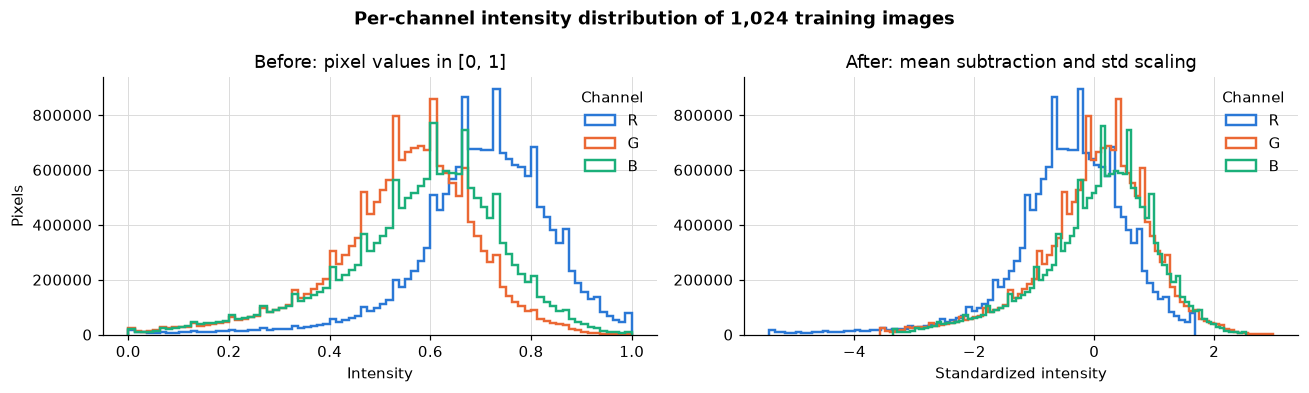

READY: preprocessing fitted on training data only


In [6]:
# Checkpoint 6: 128x128 cache and training-only channel statistics.
cnn_cache = load_or_build_cache(metadata, image_index, CNN_IMAGE_SIZE, CACHE_DIR)
train_indices = train_frame["cache_index"].to_numpy()
cnn_mean, cnn_std = compute_channel_stats(cnn_cache, train_indices)
CNN_MEAN, CNN_STD = cnn_mean.tolist(), cnn_std.tolist()
cnn_train_transform, cnn_eval_transform = build_transform_pair(CNN_IMAGE_SIZE, CNN_MEAN, CNN_STD, augment=True)

# Check: after normalization the training pixels have mean ~0 and std ~1 per channel.
sample = cnn_cache[torch.tensor(train_indices[:1024])]
normalized = torch.stack([cnn_eval_transform(image) for image in sample])
stats = pd.DataFrame({
    "channel": ["R", "G", "B"],
    "training_mean": CNN_MEAN,
    "training_std": CNN_STD,
    "mean_after": normalized.mean(dim=(0, 2, 3)).tolist(),
    "std_after": normalized.std(dim=(0, 2, 3)).tolist(),
})
display(stats.style.format("{:.4f}", subset=stats.columns[1:]).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
raw = sample.float() / 255.0
for channel, (name, color) in enumerate(zip("RGB", SERIES[:3])):
    axes[0].hist(raw[:, channel].flatten().numpy(), bins=80, histtype="step", color=color, linewidth=1.6, label=name)
    axes[1].hist(normalized[:, channel].flatten().numpy(), bins=80, histtype="step", color=color, linewidth=1.6, label=name)
axes[0].set(title="Before: pixel values in [0, 1]", xlabel="Intensity", ylabel="Pixels")
axes[1].set(title="After: mean subtraction and std scaling", xlabel="Standardized intensity")
for axis in axes:
    axis.legend(title="Channel", frameon=False)
fig.suptitle("Per-channel intensity distribution of 1,024 training images", weight="bold")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "preprocessing_histograms.png", bbox_inches="tight")
plt.show()
del sample, normalized, raw
print("READY: preprocessing fitted on training data only")

## 1.2 Data augmentation

| Augmentation | Setting | Why the label is preserved |
|---|---|---|
| Random resized crop | 75–100% of the area | Zoom and framing change, the lesion stays |
| Horizontal/vertical flip | p = 0.5 | Lesions have no fixed orientation |
| Rotation | ±20° | The camera can rotate freely |
| Colour jitter | mild (±15% brightness/contrast) | Lighting varies; kept small because colour is diagnostic |

Every training image is re-augmented each epoch. Validation and test images are only normalized.

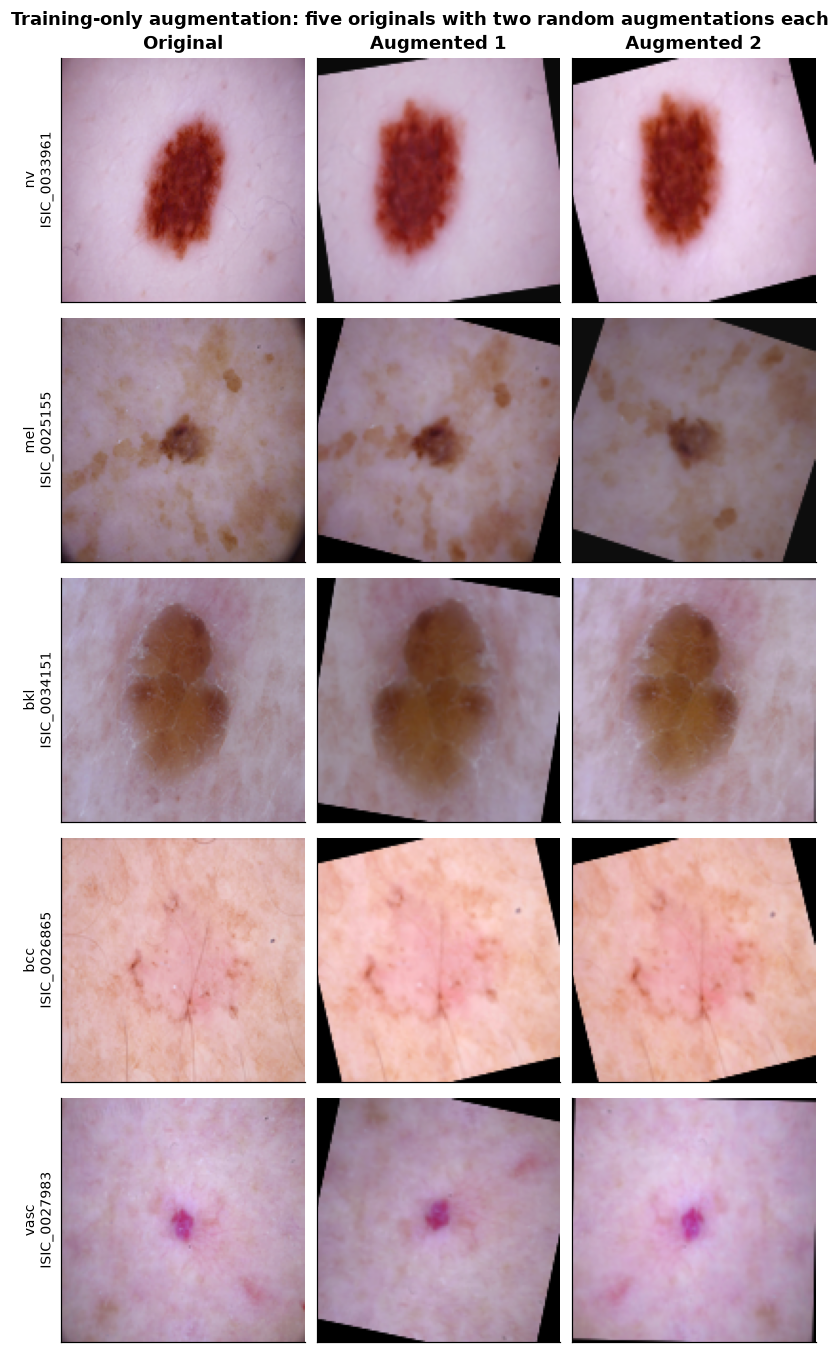

train     : 6,409 images, augmentation=ON
validation: 1,603 images, augmentation=off
test      : 2,003 images, augmentation=off
READY: augmentation is applied to training data only


In [7]:
# Checkpoint 7: five original training images, each with two augmented versions.
augment = build_augmentation(CNN_IMAGE_SIZE)
preview_classes = ["nv", "mel", "bkl", "bcc", "vasc"]
preview_rows = [train_frame[train_frame["dx"] == code].sample(1, random_state=SEED).iloc[0] for code in preview_classes]

torch.manual_seed(SEED)
fig, axes = plt.subplots(len(preview_rows), 3, figsize=(7.5, 12.5))
for row, record in enumerate(preview_rows):
    original = cnn_cache[int(record["cache_index"])]
    versions = [original, augment(original), augment(original)]
    for col, (image, title) in enumerate(zip(versions, ["Original", "Augmented 1", "Augmented 2"])):
        axes[row, col].imshow(image.permute(1, 2, 0).numpy())
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([]); axes[row, col].grid(False)
        if row == 0:
            axes[row, col].set_title(title, weight="bold")
    axes[row, 0].set_ylabel(f"{record['dx']}\n{record['image_id']}", fontsize=9)
fig.suptitle("Training-only augmentation: five originals with two random augmentations each", weight="bold")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "augmentation_examples.png", bbox_inches="tight")
plt.show()

check_loaders = make_loaders(split_manifest, cnn_cache, label_to_index, cnn_train_transform, cnn_eval_transform,
                             BATCH_SIZE, 0, SEED, False, splits=("train", "validation", "test"))
for name, loader in check_loaders.items():
    augmented = loader.dataset.transform is cnn_train_transform
    print(f"{name:10s}: {len(loader.dataset):5,} images, augmentation={'ON' if augmented else 'off'}")
assert check_loaders["train"].dataset.transform is cnn_train_transform
assert check_loaders["validation"].dataset.transform is cnn_eval_transform
assert check_loaders["test"].dataset.transform is cnn_eval_transform
del check_loaders
print("READY: augmentation is applied to training data only")

## 1.3 CNN architecture

- **4 blocks** of [Conv3×3 → BatchNorm → ReLU] × 2 + MaxPool 2×2, giving **8 conv layers**.
- **Downsampling:** max pooling halves the size each block (128 → 8) while the filters double (32 → 256).
- **Head:** global average pooling → Dropout → Linear(128) → ReLU → Dropout → Linear(7 logits).
- **Initialization:** He initialization, which suits ReLU.

Global average pooling keeps the head small (1.2 M parameters in total with 32 filters, vs 6.4 M for the MLP).

layer,type,description,output_shape,trainable_parameters,total_parameters
input,Input,RGB image,3 x 128 x 128,0,0
block1,ConvBlock,2 x [Conv3x3 + BN + ReLU] + MaxPool2x2,32 x 64 x 64,"10,208","10,208"
block2,ConvBlock,2 x [Conv3x3 + BN + ReLU] + MaxPool2x2,64 x 32 x 32,"55,552","55,552"
block3,ConvBlock,2 x [Conv3x3 + BN + ReLU] + MaxPool2x2,128 x 16 x 16,"221,696","221,696"
block4,ConvBlock,2 x [Conv3x3 + BN + ReLU] + MaxPool2x2,256 x 8 x 8,"885,760","885,760"
global_avg_pool,AdaptiveAvgPool2d,AdaptiveAvgPool2d,256 x 1 x 1,0,0
classifier.0,Flatten,Flatten,256,0,0
classifier.1,Dropout,Dropout p=0.3,256,0,0
classifier.2,Linear,Linear 256 -> 128,128,"32,896","32,896"
classifier.3,ReLU,ReLU,128,0,0


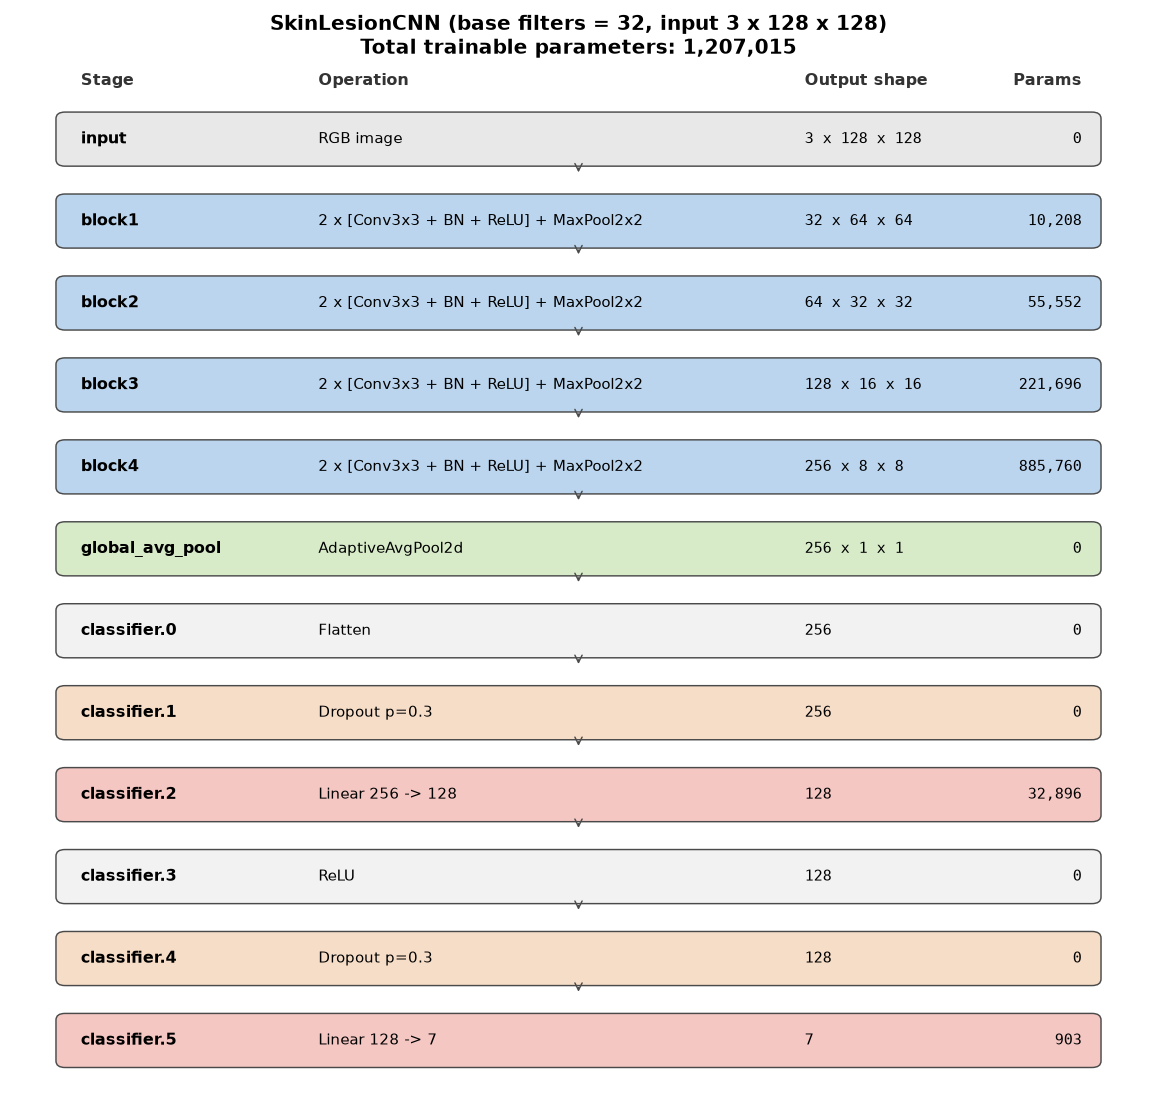

Layer-level view (every leaf module):


layer,type,output_shape,trainable_parameters,total_parameters
features.0.0,Conv2d,32 x 128 x 128,864,864
features.0.1,BatchNorm2d,32 x 128 x 128,64,64
features.0.2,ReLU,32 x 128 x 128,0,0
features.0.3,Conv2d,32 x 128 x 128,"9,216","9,216"
features.0.4,BatchNorm2d,32 x 128 x 128,64,64
features.0.5,ReLU,32 x 128 x 128,0,0
features.0.6,MaxPool2d,32 x 64 x 64,0,0
features.1.0,Conv2d,64 x 64 x 64,"18,432","18,432"
features.1.1,BatchNorm2d,64 x 64 x 64,128,128
features.1.2,ReLU,64 x 64 x 64,0,0


READY: 8 convolutional layers, 1,207,015 trainable parameters


In [8]:
# Checkpoint 8: architecture table and diagram with output shapes and trainable parameters.
preview_cnn = SkinLesionCNN(NUM_CLASSES, base_filters=32, dropout=0.3)
block_table = cnn_block_summary(preview_cnn, (3, CNN_IMAGE_SIZE, CNN_IMAGE_SIZE))
display(block_table.style.format({"trainable_parameters": "{:,}", "total_parameters": "{:,}"}).hide(axis="index"))
fig = draw_architecture(block_table, "SkinLesionCNN (base filters = 32, input 3 x 128 x 128)",
                        FIGURE_DIR / "cnn_architecture.png")
plt.show()

layer_table = model_summary(preview_cnn, (3, CNN_IMAGE_SIZE, CNN_IMAGE_SIZE))
print("Layer-level view (every leaf module):")
display(layer_table.style.format({"trainable_parameters": "{:,}", "total_parameters": "{:,}"}).hide(axis="index"))
conv_layers = int((layer_table["type"] == "Conv2d").sum())
total_params = int(layer_table["trainable_parameters"].sum())
assert conv_layers >= 4
print(f"READY: {conv_layers} convolutional layers, {total_params:,} trainable parameters")
del preview_cnn

## 1.4 Hyperparameter tuning

Five settings vary the **learning rate**, the **dropout** probability, and the **number of filters**.

All runs share the same recipe:
- weighted cross-entropy, Adam, weight decay 1e-4, batch size 64;
- the learning rate is halved when validation loss plateaus for 3 epochs;
- early stopping on validation macro-F1 (patience 10, at most 40 epochs).

In [9]:
# Checkpoint 9: reusable CNN training routine (training and validation only).
from torch.optim.lr_scheduler import ReduceLROnPlateau

def plateau_scheduler(optimizer, patience):
    return ReduceLROnPlateau(optimizer, mode="min", factor=PLATEAU_FACTOR, patience=patience, min_lr=MIN_LR)

def build_cnn(config):
    return SkinLesionCNN(NUM_CLASSES, base_filters=config["base_filters"], dropout=config["dropout"])

def cnn_loaders(splits=("train", "validation"), augment_train=True, shuffle_train=True):
    train_transform = cnn_train_transform if augment_train else cnn_eval_transform
    return make_loaders(split_manifest, cnn_cache, label_to_index, train_transform, cnn_eval_transform,
                        BATCH_SIZE, NUM_WORKERS, SEED, DEVICE.type == "cuda", splits=splits,
                        shuffle_train=shuffle_train)

def replay_log(store, name):
    # Print the saved epoch log of a completed run (used when results are reloaded, not retrained).
    summary, history = store.summary(name), store.history(name)
    print("=" * 100)
    print(f"LOADED {name}: trained earlier; epoch log from {store.log_path(name).relative_to(PROJECT_ROOT)} "
          f"(* = restored epoch)")
    for row in history.itertuples():
        marker = " *" if row.epoch == summary["best_epoch"] else ""
        print(f"Epoch {row.epoch:02d} | lr {row.learning_rate:.2e} | train loss {row.train_loss:.4f} "
              f"acc {row.train_accuracy:.4f} F1 {row.train_macro_f1:.4f} | val loss {row.validation_loss:.4f} "
              f"acc {row.validation_accuracy:.4f} F1 {row.validation_macro_f1:.4f}{marker}")
    print(f"Restored epoch {summary['best_epoch']} (monitor: {summary['monitor']}); "
          f"training stopped after epoch {summary['stopped_epoch']}.")
    return summary

def run_cnn(name, config, monitor, max_epochs, patience):
    if PART1.is_complete(name) and not FORCE_RERUN:
        return replay_log(PART1, name)
    print("=" * 100)
    print(f"RUN {name}: {config}, monitor={monitor}, max_epochs={max_epochs}, patience={patience}")
    set_global_seed(SEED)
    model = build_cnn(config)
    loaders = cnn_loaders()
    optimizer = build_optimizer(OPTIMIZER_NAME, model.parameters(), config["learning_rate"], WEIGHT_DECAY)
    scheduler = plateau_scheduler(optimizer, CNN_PLATEAU_PATIENCE)
    result = fit(model, loaders["train"], loaders["validation"], criterion, optimizer, DEVICE, max_epochs,
                 EarlyStopping(monitor, patience), scheduler, PART1.log_path(name), USE_AMP)
    record_config = {**config, "image_size": CNN_IMAGE_SIZE, "max_epochs": max_epochs, "patience": patience,
                     "loss": LOSS_NAME, "optimizer": OPTIMIZER_NAME, "weight_decay": WEIGHT_DECAY,
                     "mean": CNN_MEAN, "std": CNN_STD}
    summary = PART1.record(name, model, result, record_config)
    del model, loaders, optimizer
    gc.collect(); torch.cuda.empty_cache()
    return summary

print("READY: CNN training routine defined")

READY: CNN training routine defined


In [10]:
# Checkpoint 10: train the five hyperparameter settings (long-running; resumable).
HP_SETTINGS = {
    "S1": {"learning_rate": 1e-3, "dropout": 0.3, "base_filters": 32},
    "S2": {"learning_rate": 3e-4, "dropout": 0.3, "base_filters": 32},
    "S3": {"learning_rate": 1e-3, "dropout": 0.5, "base_filters": 32},
    "S4": {"learning_rate": 1e-3, "dropout": 0.3, "base_filters": 64},
    "S5": {"learning_rate": 3e-4, "dropout": 0.5, "base_filters": 64},
}
for setting, config in HP_SETTINGS.items():
    run_cnn(f"tune_{setting}", config, "validation_macro_f1", TUNING_MAX_EPOCHS, TUNING_PATIENCE)
print("READY: all hyperparameter settings completed")

LOADED tune_S1: trained earlier; epoch log from results/milestone_03/part1_cnn/logs/tune_S1.csv (* = restored epoch)
Epoch 01 | lr 1.00e-03 | train loss 1.8499 acc 0.3002 F1 0.1862 | val loss 1.4693 acc 0.4367 F1 0.2381
Epoch 02 | lr 1.00e-03 | train loss 1.7359 acc 0.3637 F1 0.2150 | val loss 1.8404 acc 0.1609 F1 0.1462
Epoch 03 | lr 1.00e-03 | train loss 1.6752 acc 0.3726 F1 0.2311 | val loss 1.5557 acc 0.3986 F1 0.2640
Epoch 04 | lr 1.00e-03 | train loss 1.6337 acc 0.3940 F1 0.2524 | val loss 1.2635 acc 0.5022 F1 0.2975
Epoch 05 | lr 1.00e-03 | train loss 1.5668 acc 0.4300 F1 0.2633 | val loss 1.4047 acc 0.4579 F1 0.2875
Epoch 06 | lr 1.00e-03 | train loss 1.5338 acc 0.4133 F1 0.2646 | val loss 1.4047 acc 0.4460 F1 0.2962
Epoch 07 | lr 1.00e-03 | train loss 1.5275 acc 0.4210 F1 0.2709 | val loss 1.3388 acc 0.4654 F1 0.3111
Epoch 08 | lr 1.00e-03 | train loss 1.4776 acc 0.4497 F1 0.2828 | val loss 1.2740 acc 0.4835 F1 0.3003
Epoch 09 | lr 5.00e-04 | train loss 1.4219 acc 0.4682 F1 0.

setting,learning_rate,dropout,base_filters,trainable_parameters,best_epoch,stopped_epoch,validation_macro_f1,validation_accuracy,validation_loss,elapsed_seconds
S5,3e-04,0.500000,64,"4,753,863",36,40,0.4589,0.5795,1.0035,305
S2,3e-04,0.300000,32,"1,207,015",36,40,0.4520,0.5858,1.0034,150
S1,1e-03,0.300000,32,"1,207,015",36,40,0.4384,0.5577,1.1172,154
S4,1e-03,0.300000,64,"4,753,863",37,40,0.3790,0.5259,1.2460,305
S3,1e-03,0.500000,32,"1,207,015",37,40,0.3724,0.5172,1.1812,151


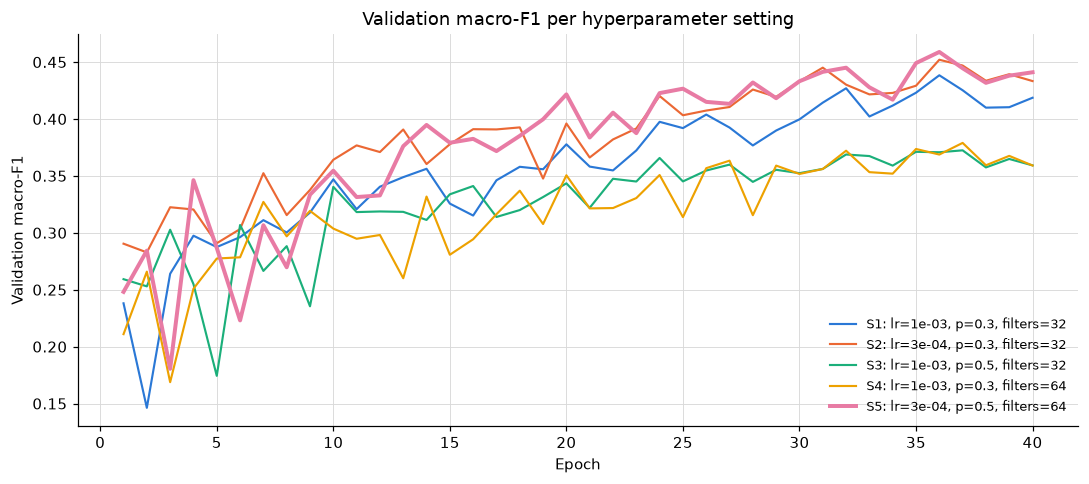

SELECTED: S5 -> {'learning_rate': 0.0003, 'dropout': 0.5, 'base_filters': 64} (validation macro-F1 only; test data untouched)


In [11]:
# Checkpoint 11: record each setting and its best validation score; select the best setting.
tuning = PART1.table([f"tune_{s}" for s in HP_SETTINGS])
tuning.insert(0, "setting", list(HP_SETTINGS))
tuning_view = tuning[["setting", "learning_rate", "dropout", "base_filters", "trainable_parameters",
                      "best_epoch", "stopped_epoch", "validation_macro_f1", "validation_accuracy",
                      "validation_loss", "elapsed_seconds"]]
tuning_view.to_csv(RESULTS_DIR / "hyperparameter_tuning.csv", index=False)
display(tuning_view.sort_values("validation_macro_f1", ascending=False).style.format({
    "learning_rate": "{:.0e}", "trainable_parameters": "{:,}", "validation_macro_f1": "{:.4f}",
    "validation_accuracy": "{:.4f}", "validation_loss": "{:.4f}", "elapsed_seconds": "{:.0f}",
}).highlight_max(subset=["validation_macro_f1"], color="#d6e6f8").hide(axis="index"))

best_setting = tuning.sort_values(["validation_macro_f1", "validation_loss"], ascending=[False, True]).iloc[0]["setting"]
BEST_CNN_CONFIG = HP_SETTINGS[best_setting]

fig, axis = plt.subplots(figsize=(10, 4.5))
for color, setting in zip(SERIES, HP_SETTINGS):
    history = PART1.history(f"tune_{setting}")
    cfg = HP_SETTINGS[setting]
    label = f"{setting}: lr={cfg['learning_rate']:.0e}, p={cfg['dropout']}, filters={cfg['base_filters']}"
    axis.plot(history["epoch"], history["validation_macro_f1"], color=color, label=label,
              linewidth=2.6 if setting == best_setting else 1.4)
axis.set(title="Validation macro-F1 per hyperparameter setting", xlabel="Epoch", ylabel="Validation macro-F1")
axis.legend(frameon=False, fontsize=8.5, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hyperparameter_tuning_curves.png", bbox_inches="tight")
plt.show()
print(f"SELECTED: {best_setting} -> {BEST_CNN_CONFIG} (validation macro-F1 only; test data untouched)")

### Tuning result

- A **lower learning rate (3e-4)** helped at both widths.
- At 1e-3, more filters (S4) or more dropout (S3) hurt.
- **S5** (lr 3e-4, dropout 0.5, 64 filters) is best at **0.459**, just ahead of S2 (0.452). It is selected.

## 1.5 Early stopping

S5 is retrained for up to 60 epochs, once with each stopping criterion:

| Monitor | Goal |
|---|---|
| Training accuracy | maximize |
| Validation accuracy | maximize |
| Validation loss | minimize |

- **Patience:** 10 epochs. Each run restores its best epoch.
- **Same path:** all three runs share the same seed, so they follow the same path and differ only in when they stop.
- **Selection:** the restored model with the highest **validation macro-F1** wins.

In [12]:
# Checkpoint 12: train the best setting with three early-stopping monitors.
ES_MONITORS = ["train_accuracy", "validation_accuracy", "validation_loss"]
for monitor in ES_MONITORS:
    run_cnn(f"es_{monitor}", BEST_CNN_CONFIG, monitor, ES_MAX_EPOCHS, ES_PATIENCE)
print("READY: early-stopping runs completed")

LOADED es_train_accuracy: trained earlier; epoch log from results/milestone_03/part1_cnn/logs/es_train_accuracy.csv (* = restored epoch)
Epoch 01 | lr 3.00e-04 | train loss 2.1060 acc 0.2866 F1 0.1658 | val loss 1.4213 acc 0.4492 F1 0.2481
Epoch 02 | lr 3.00e-04 | train loss 1.7610 acc 0.3888 F1 0.2135 | val loss 1.3565 acc 0.4797 F1 0.2843
Epoch 03 | lr 3.00e-04 | train loss 1.6921 acc 0.4054 F1 0.2420 | val loss 1.9260 acc 0.2308 F1 0.1805
Epoch 04 | lr 3.00e-04 | train loss 1.6646 acc 0.3824 F1 0.2385 | val loss 1.3488 acc 0.4779 F1 0.3462
Epoch 05 | lr 3.00e-04 | train loss 1.5735 acc 0.4375 F1 0.2716 | val loss 1.5672 acc 0.4161 F1 0.2868
Epoch 06 | lr 3.00e-04 | train loss 1.5596 acc 0.4308 F1 0.2659 | val loss 1.7015 acc 0.3007 F1 0.2230
Epoch 07 | lr 3.00e-04 | train loss 1.5567 acc 0.4414 F1 0.2731 | val loss 1.3665 acc 0.4442 F1 0.3067
Epoch 08 | lr 3.00e-04 | train loss 1.5338 acc 0.4467 F1 0.2794 | val loss 1.4039 acc 0.4167 F1 0.2697
Epoch 09 | lr 1.50e-04 | train loss 1.4

monitor,best_epoch,stopped_epoch,best_monitor_value,train_accuracy,validation_accuracy,validation_loss,validation_macro_f1
train_accuracy,41,51,0.5759,0.5759,0.5745,1.0156,0.4486
validation_accuracy,25,35,0.5721,0.5422,0.5721,1.0303,0.4266
validation_loss,25,35,1.0303,0.5422,0.5721,1.0303,0.4266


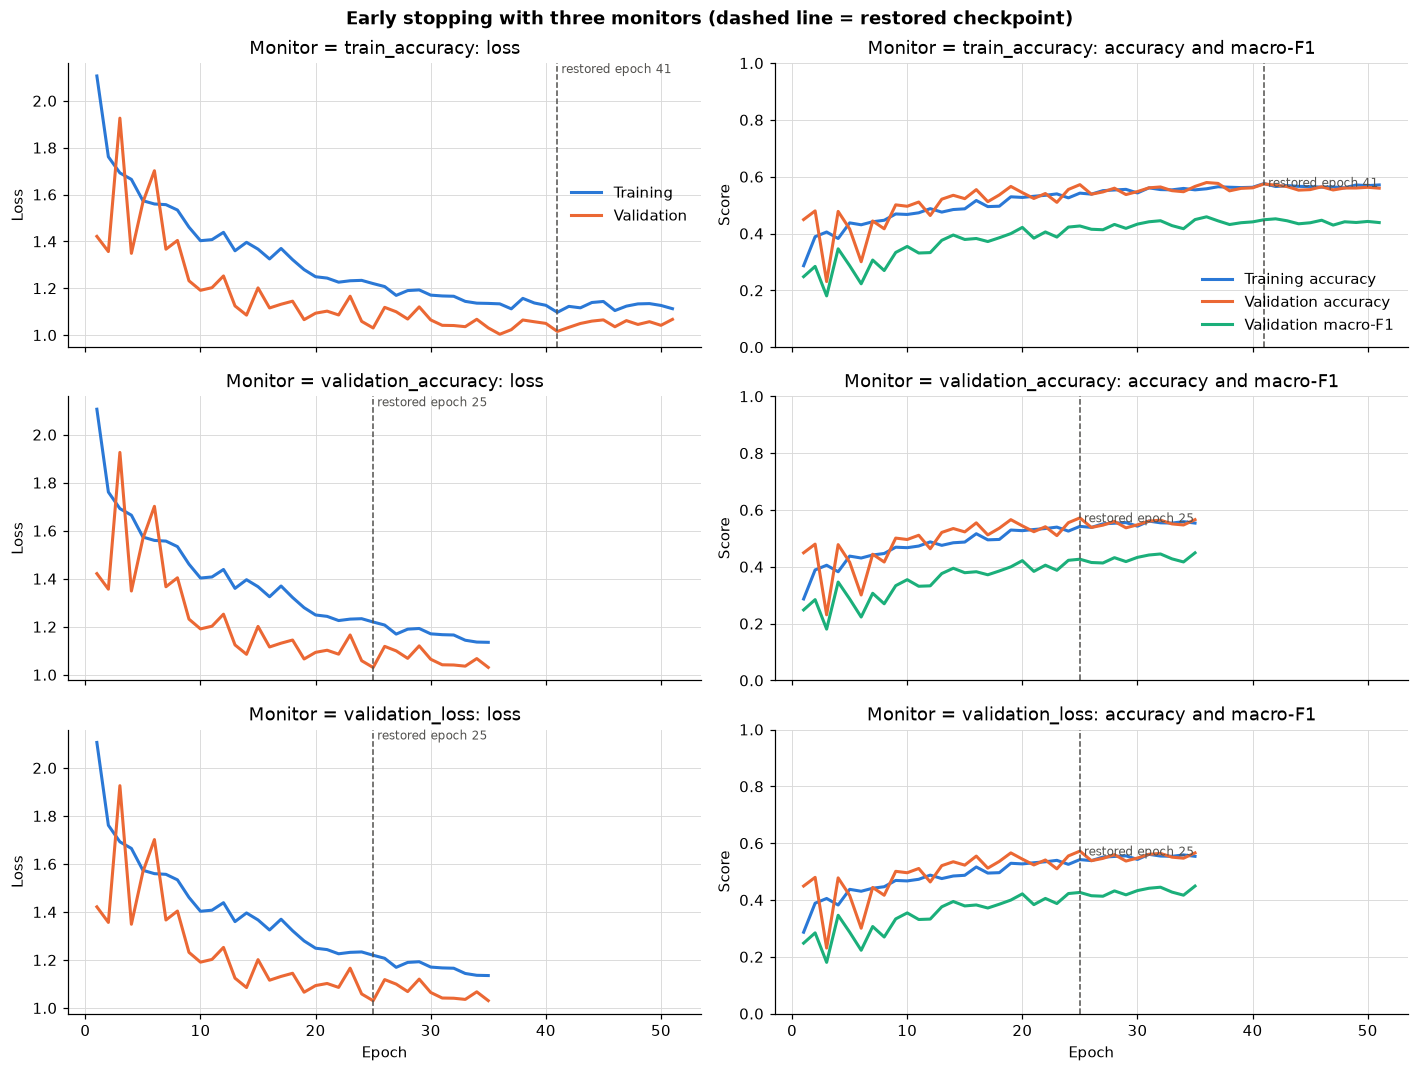

SELECTED: early stopping on train_accuracy (validation macro-F1 0.4486, restored epoch 41)


In [13]:
# Checkpoint 13: compare the restored models on the validation set and select one.
es_table = PART1.table([f"es_{m}" for m in ES_MONITORS])
es_view = es_table[["monitor", "best_epoch", "stopped_epoch", "best_monitor_value", "train_accuracy",
                    "validation_accuracy", "validation_loss", "validation_macro_f1"]]
es_view.to_csv(RESULTS_DIR / "early_stopping_comparison.csv", index=False)
display(es_view.style.format({c: "{:.4f}" for c in es_view.columns[3:]})
        .highlight_max(subset=["validation_macro_f1"], color="#d6e6f8").hide(axis="index"))

selected = es_table.sort_values(["validation_macro_f1", "validation_loss"], ascending=[False, True]).iloc[0]
SELECTED_MONITOR = selected["monitor"]

fig, axes = plt.subplots(len(ES_MONITORS), 2, figsize=(13, 3.3 * len(ES_MONITORS)), sharex=True)
for row, monitor in enumerate(ES_MONITORS):
    history = PART1.history(f"es_{monitor}")
    best_epoch = int(es_table.loc[es_table["monitor"] == monitor, "best_epoch"].iloc[0])
    axes[row, 0].plot(history["epoch"], history["train_loss"], color=TRAIN_COLOR, label="Training")
    axes[row, 0].plot(history["epoch"], history["validation_loss"], color=VAL_COLOR, label="Validation")
    axes[row, 1].plot(history["epoch"], history["train_accuracy"], color=TRAIN_COLOR, label="Training accuracy")
    axes[row, 1].plot(history["epoch"], history["validation_accuracy"], color=VAL_COLOR, label="Validation accuracy")
    axes[row, 1].plot(history["epoch"], history["validation_macro_f1"], color=SERIES[2], label="Validation macro-F1")
    for axis in axes[row]:
        axis.axvline(best_epoch, color="#52514e", linestyle="--", linewidth=1)
        axis.text(best_epoch, axis.get_ylim()[1], f" restored epoch {best_epoch}", va="top", fontsize=8, color="#52514e")
    axes[row, 0].set(ylabel="Loss", title=f"Monitor = {monitor}: loss")
    axes[row, 1].set(ylabel="Score", ylim=(0, 1), title=f"Monitor = {monitor}: accuracy and macro-F1")
for axis in axes[-1]:
    axis.set_xlabel("Epoch")
axes[0, 0].legend(frameon=False); axes[0, 1].legend(frameon=False, loc="lower right")
fig.suptitle("Early stopping with three monitors (dashed line = restored checkpoint)", weight="bold")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "early_stopping_curves.png", bbox_inches="tight")
plt.show()
print(f"SELECTED: early stopping on {SELECTED_MONITOR} "
      f"(validation macro-F1 {selected['validation_macro_f1']:.4f}, restored epoch {selected['best_epoch']})")

### Early-stopping result

- **Validation monitors stopped early.** Validation accuracy and loss are noisy, because the validation split is small (19 df images). Both stopped at epoch 35 and restored epoch 25.
- **Training accuracy ran longer.** It is smoother and kept improving as the learning rate dropped, so it ran to epoch 51 and restored epoch 41.
- **Selected:** the training-accuracy model, with the best validation macro-F1 (**0.449** vs 0.427). No overfitting was visible: training and validation accuracy were 0.576 vs 0.575.

## 1.6 Model saving

The selected checkpoint is saved as `part1_cnn/checkpoints/cnn_best.pt`, with its log in `logs/cnn_best.csv`. It stores the weights, history, best epoch, and configuration. It is reloaded below to confirm the validation score.

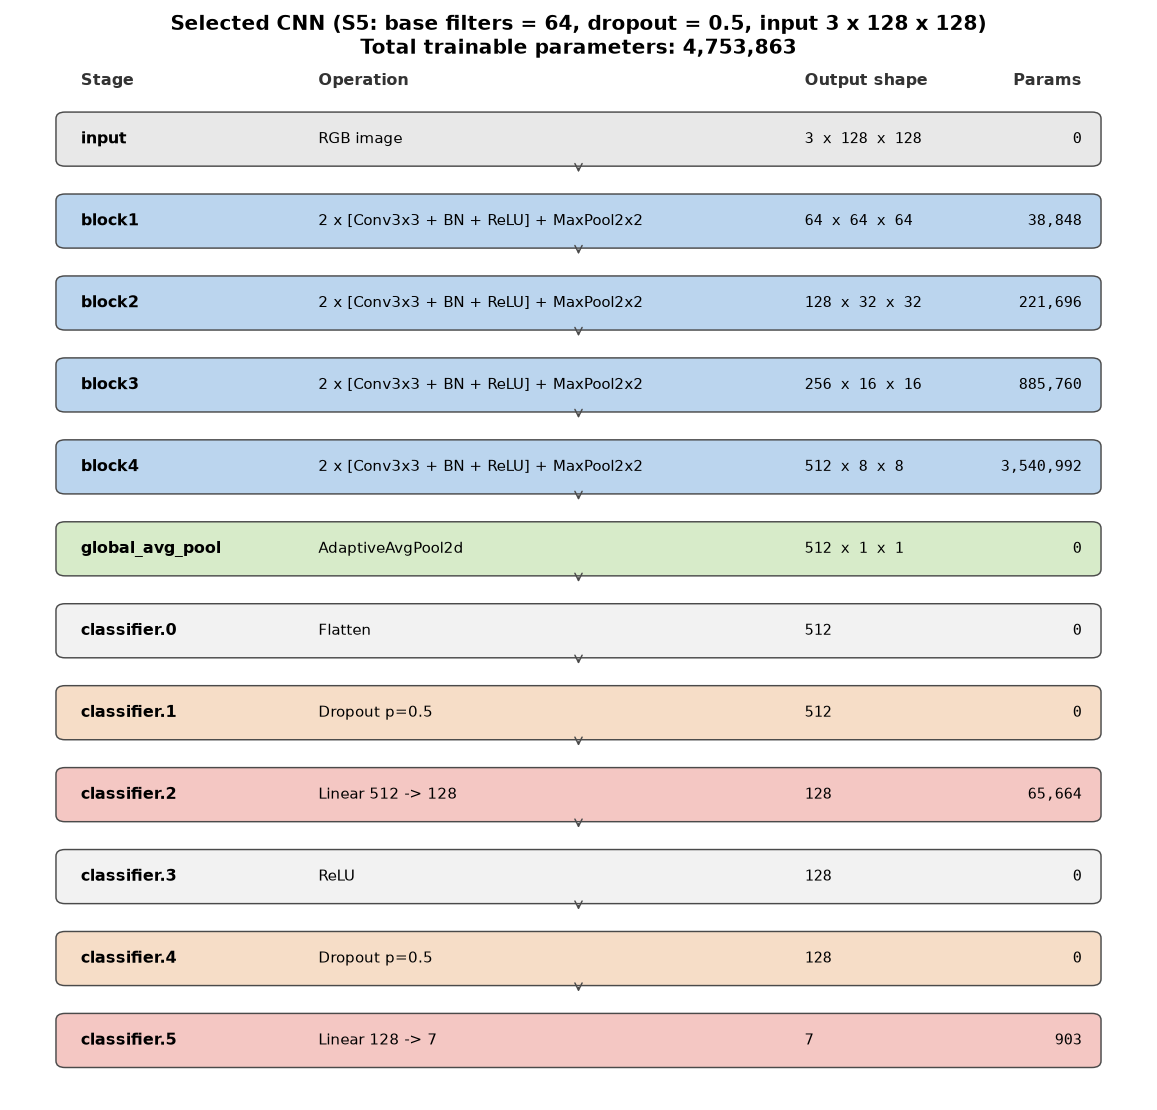

Checkpoint: results/milestone_03/part1_cnn/checkpoints/cnn_best.pt (18.2 MiB)
Stored metadata: {"learning_rate": 0.0003, "dropout": 0.5, "base_filters": 64, "image_size": 128, "max_epochs": 60, "patience": 10, "loss": "cross_entropy", "optimizer": "adam", "weight_decay": 0.0001}
Logged validation macro-F1 at epoch 41: 0.4486; reloaded model: 0.4486
READY: checkpoint and logs saved and verified


In [14]:
# Checkpoint 14: save the selected checkpoint and logs; verify by reloading.
CNN_BEST_CHECKPOINT = PART1.checkpoint_dir / "cnn_best.pt"
shutil.copy2(PART1.checkpoint_path(f"es_{SELECTED_MONITOR}"), CNN_BEST_CHECKPOINT)
shutil.copy2(PART1.log_path(f"es_{SELECTED_MONITOR}"), PART1.log_dir / "cnn_best.csv")
shutil.copy2(PART1.summary_path(f"es_{SELECTED_MONITOR}"), PART1.summary_dir / "cnn_best.json")

cnn_model = build_cnn(BEST_CNN_CONFIG)
cnn_checkpoint = load_checkpoint(CNN_BEST_CHECKPOINT, cnn_model, map_location=DEVICE)
cnn_model.to(DEVICE)
selected_table = cnn_block_summary(cnn_model, (3, CNN_IMAGE_SIZE, CNN_IMAGE_SIZE))
draw_architecture(selected_table, f"Selected CNN ({best_setting}: base filters = {BEST_CNN_CONFIG['base_filters']}, "
                  f"dropout = {BEST_CNN_CONFIG['dropout']}, input 3 x 128 x 128)",
                  FIGURE_DIR / "cnn_architecture_selected.png")
plt.show()
validation_loader = cnn_loaders(splits=("validation",))["validation"]
reloaded = evaluate(cnn_model, validation_loader, criterion, DEVICE, USE_AMP)
logged = pd.DataFrame(cnn_checkpoint["history"]).set_index("epoch").loc[cnn_checkpoint["best_epoch"]]
print(f"Checkpoint: {CNN_BEST_CHECKPOINT.relative_to(PROJECT_ROOT)} "
      f"({CNN_BEST_CHECKPOINT.stat().st_size / 2**20:.1f} MiB)")
print(f"Stored metadata: {json.dumps({k: v for k, v in cnn_checkpoint['metadata'].items() if k not in ('mean', 'std')})}")
print(f"Logged validation macro-F1 at epoch {cnn_checkpoint['best_epoch']}: {logged['validation_macro_f1']:.4f}; "
      f"reloaded model: {reloaded['macro_f1']:.4f}")
assert abs(reloaded["macro_f1"] - logged["validation_macro_f1"]) < 5e-3
print("READY: checkpoint and logs saved and verified")

## 1.7 Test evaluation

All Part 1 choices are fixed. The selected CNN is tested once and compared with the Milestone 2 MLP.

model,input,trainable_parameters,test_loss,test_accuracy,test_macro_f1
Milestone 2 Shallow MLP,64 x 64,"6,359,815",1.0424,0.5861,0.3890
"CNN from scratch (S5, early stopping on train_accuracy)",128 x 128,"4,753,863",0.9902,0.5821,0.4537


              precision    recall  f1-score   support

       akiec      0.295     0.500     0.371        66
         bcc      0.514     0.524     0.519       103
         bkl      0.338     0.486     0.399       220
          df      0.079     0.522     0.137        23
         mel      0.303     0.590     0.400       222
          nv      0.969     0.600     0.741      1341
        vasc      0.463     0.893     0.610        28

    accuracy                          0.582      2003
   macro avg      0.423     0.588     0.454      2003
weighted avg      0.763     0.582     0.633      2003



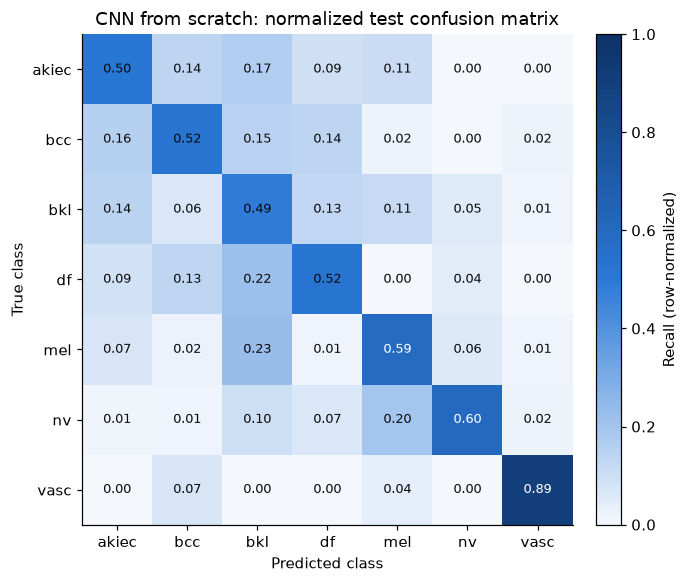

READY: CNN test macro-F1 0.4537 vs MLP 0.3890 (+0.0647)


In [15]:
# Checkpoint 15: one-time test evaluation of the selected CNN.
test_loader = cnn_loaders(splits=("test",))["test"]
cnn_test = evaluate(cnn_model, test_loader, criterion, DEVICE, USE_AMP)
comparison = pd.DataFrame([
    {"model": f"Milestone 2 {MLP_TEST['network']}", "input": "64 x 64",
     "trainable_parameters": int(MLP_TEST["trainable_parameters"]), "test_loss": MLP_TEST["test_loss"],
     "test_accuracy": MLP_TEST["test_accuracy"], "test_macro_f1": MLP_TEST["test_macro_f1"]},
    {"model": f"CNN from scratch ({best_setting}, early stopping on {SELECTED_MONITOR})", "input": "128 x 128",
     "trainable_parameters": sum(p.numel() for p in cnn_model.parameters()), "test_loss": cnn_test["loss"],
     "test_accuracy": cnn_test["accuracy"], "test_macro_f1": cnn_test["macro_f1"]},
])
comparison.to_csv(RESULTS_DIR / "part1_test_comparison.csv", index=False)
display(comparison.style.format({"trainable_parameters": "{:,}", "test_loss": "{:.4f}", "test_accuracy": "{:.4f}",
                                 "test_macro_f1": "{:.4f}"}).hide(axis="index"))

print(classification_report(cnn_test["targets"], cnn_test["predictions"], labels=list(range(NUM_CLASSES)),
                            target_names=class_codes, digits=3, zero_division=0))

def plot_confusion(targets, predictions, title, path):
    matrix = confusion_matrix(targets, predictions, labels=list(range(NUM_CLASSES)), normalize="true")
    fig, axis = plt.subplots(figsize=(6.4, 5.4))
    image = axis.imshow(matrix, cmap=SEQUENTIAL, vmin=0, vmax=1)
    axis.grid(False)
    axis.set_xticks(range(NUM_CLASSES), class_codes); axis.set_yticks(range(NUM_CLASSES), class_codes)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            axis.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                      color="white" if matrix[i, j] > 0.55 else "#0b0b0b")
    axis.set(title=title, xlabel="Predicted class", ylabel="True class")
    fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04, label="Recall (row-normalized)")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()

plot_confusion(cnn_test["targets"], cnn_test["predictions"], "CNN from scratch: normalized test confusion matrix",
               FIGURE_DIR / "cnn_test_confusion_matrix.png")

test_frame = split_manifest[split_manifest["split"] == "test"].reset_index(drop=True)
cnn_predictions = test_frame[["image_id", "lesion_id", "dx"]].copy()
cnn_predictions["prediction"] = [index_to_label[int(i)] for i in cnn_test["predictions"]]
for index, code in enumerate(class_codes):
    cnn_predictions[f"p_{code}"] = cnn_test["probabilities"][:, index]
cnn_predictions.to_csv(RESULTS_DIR / "cnn_test_predictions.csv", index=False)
improvement = cnn_test["macro_f1"] - MLP_TEST["test_macro_f1"]
print(f"READY: CNN test macro-F1 {cnn_test['macro_f1']:.4f} vs MLP {MLP_TEST['test_macro_f1']:.4f} "
      f"({improvement:+.4f})")

### Part 1 result

- **The CNN beats the MLP:** test macro-F1 **0.454 vs 0.389**, with fewer parameters (4.75 M vs 6.36 M). Accuracy is similar (0.582 vs 0.586), because the weighted loss favours minority classes.
- **Why:** convolutions keep spatial structure and share weights; the MLP flattens the image.
- **Main confusions:** nevi → melanoma (20%) and melanoma → benign keratosis (23%). Vascular lesions are easiest (0.89).

# Part 2: Transfer learning

| Model | Replaced ImageNet layer |
|---|---|
| VGG19 | `classifier.6` (4096 → 1000) |
| ResNet-50 | `fc` (2048 → 1000) |
| MobileNetV3-Large | `classifier.3` (1280 → 1000) |

- **Input:** 224×224 with **ImageNet normalization**, the input the pretrained weights expect. Same augmentation as Part 1, training only.
- **Training:** weighted cross-entropy and Adam on trainable parameters only. The learning rate is halved on a 2-epoch plateau. Early stopping on validation macro-F1 (patience 4, at most 12 epochs).
- **Frozen BatchNorm** stays in eval mode, keeping its ImageNet statistics.
- **Checkpoints** store only the trainable layers; the frozen weights come from `torchvision`.

In [16]:
# Checkpoint 16: 224x224 cache, ImageNet normalization, and the transfer training routine.
BACKBONES = ["vgg19", "resnet50", "mobilenet_v3_large"]
BACKBONE_LABELS = {"vgg19": "VGG19", "resnet50": "ResNet-50", "mobilenet_v3_large": "MobileNetV3-Large"}
STRATEGY_LABELS = {"head": "Classifier only", "last3": "Last 3 layers", "extended": "Added layers"}

transfer_cache = load_or_build_cache(metadata, image_index, TRANSFER_IMAGE_SIZE, CACHE_DIR)
tl_train_transform, tl_eval_transform = build_transform_pair(TRANSFER_IMAGE_SIZE, IMAGENET_MEAN, IMAGENET_STD, augment=True)

def transfer_loaders(splits=("train", "validation"), augment_train=True, shuffle_train=True):
    train_transform = tl_train_transform if augment_train else tl_eval_transform
    return make_loaders(split_manifest, transfer_cache, label_to_index, train_transform, tl_eval_transform,
                        BATCH_SIZE, NUM_WORKERS, SEED, DEVICE.type == "cuda", splits=splits,
                        shuffle_train=shuffle_train)

def run_transfer(name, backbone, strategy, learning_rate):
    if PART2.is_complete(name) and not FORCE_RERUN:
        return replay_log(PART2, name)
    print("=" * 100)
    print(f"RUN {name}: backbone={backbone}, strategy={strategy}, lr={learning_rate:g}")
    set_global_seed(SEED)
    model = build_transfer_model(backbone, strategy, NUM_CLASSES)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = build_optimizer(OPTIMIZER_NAME, trainable, learning_rate, WEIGHT_DECAY)
    scheduler = plateau_scheduler(optimizer, TRANSFER_PLATEAU_PATIENCE)
    loaders = transfer_loaders()
    result = fit(model, loaders["train"], loaders["validation"], criterion, optimizer, DEVICE,
                 TRANSFER_MAX_EPOCHS, EarlyStopping("validation_macro_f1", TRANSFER_PATIENCE), scheduler,
                 PART2.log_path(name), USE_AMP)
    config = {"backbone": backbone, "strategy": strategy, "learning_rate": learning_rate,
              "image_size": TRANSFER_IMAGE_SIZE, "max_epochs": TRANSFER_MAX_EPOCHS, "patience": TRANSFER_PATIENCE,
              "trainable_layers": model.trainable_layers, **parameter_report(model)}
    summary = PART2.record(name, model, result, config, trainable_only=True)
    del model, loaders, optimizer, trainable
    gc.collect(); torch.cuda.empty_cache()
    return summary

def load_transfer(name):
    summary = PART2.summary(name)
    model = build_transfer_model(summary["backbone"], summary["strategy"], NUM_CLASSES)
    load_checkpoint(PART2.checkpoint_path(name), model, map_location="cpu")
    return model.to(DEVICE).eval()

print(f"READY: transfer cache {tuple(transfer_cache.shape)}, ImageNet mean={IMAGENET_MEAN}, std={IMAGENET_STD}")

READY: transfer cache (10015, 3, 224, 224), ImageNet mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)


## 2.1 Train only the new classifier

The ImageNet layer is replaced by `Linear(in_features, 7)`, and everything else is frozen. The new layer is randomly initialized, so it uses learning rate **1e-3**.

In [17]:
# Checkpoint 17: parameter budget per backbone and strategy.
budget_rows = []
for backbone in BACKBONES:
    for strategy in ("head", "last3", "extended"):
        model = build_transfer_model(backbone, strategy, NUM_CLASSES)
        budget_rows.append({"backbone": BACKBONE_LABELS[backbone], "strategy": STRATEGY_LABELS[strategy],
                            "final_linear_input": model.final_linear.in_features, **parameter_report(model)})
        del model
budget = pd.DataFrame(budget_rows)
display(budget.style.format({c: "{:,}" for c in ["total_parameters", "trainable_parameters", "frozen_parameters"]})
        .hide(axis="index"))

backbone,strategy,final_linear_input,total_parameters,trainable_parameters,frozen_parameters
VGG19,Classifier only,4096,"139,598,919","28,679","139,570,240"
VGG19,Last 3 layers,4096,"139,598,919","119,574,535","20,024,384"
VGG19,Added layers,256,"141,802,567","2,232,327","139,570,240"
ResNet-50,Classifier only,2048,"23,522,375","14,343","23,508,032"
ResNet-50,Last 3 layers,2048,"23,522,375","3,422,215","20,100,160"
ResNet-50,Added layers,256,"24,691,783","1,183,751","23,508,032"
MobileNetV3-Large,Classifier only,1280,"4,210,999","8,967","4,202,032"
MobileNetV3-Large,Last 3 layers,1280,"4,210,999","1,392,647","2,818,352"
MobileNetV3-Large,Added layers,256,"4,992,567","790,535","4,202,032"


In [18]:
# Checkpoint 18: train only the new classification layer of each backbone.
HEAD_LR = 1e-3
for backbone in BACKBONES:
    run_transfer(f"{backbone}_head", backbone, "head", HEAD_LR)
print("READY: classifier-only runs completed")

LOADED vgg19_head: trained earlier; epoch log from results/milestone_03/part2_transfer/logs/vgg19_head.csv (* = restored epoch)
Epoch 01 | lr 1.00e-03 | train loss 1.7581 acc 0.3626 F1 0.2205 | val loss 1.6994 acc 0.3250 F1 0.2155
Epoch 02 | lr 1.00e-03 | train loss 1.5910 acc 0.4491 F1 0.2739 | val loss 1.6743 acc 0.3450 F1 0.2201
Epoch 03 | lr 1.00e-03 | train loss 1.4902 acc 0.4736 F1 0.2979 | val loss 1.4808 acc 0.4398 F1 0.2569
Epoch 04 | lr 1.00e-03 | train loss 1.5202 acc 0.4444 F1 0.2939 | val loss 1.5753 acc 0.4323 F1 0.2721
Epoch 05 | lr 1.00e-03 | train loss 1.4969 acc 0.4734 F1 0.2975 | val loss 1.8966 acc 0.3044 F1 0.2110
Epoch 06 | lr 1.00e-03 | train loss 1.4349 acc 0.4703 F1 0.3078 | val loss 1.3729 acc 0.4779 F1 0.2926 *
Epoch 07 | lr 1.00e-03 | train loss 1.4017 acc 0.4793 F1 0.3191 | val loss 1.7218 acc 0.3862 F1 0.2241
Epoch 08 | lr 1.00e-03 | train loss 1.4469 acc 0.4790 F1 0.3101 | val loss 1.6811 acc 0.3656 F1 0.2168
Epoch 09 | lr 1.00e-03 | train loss 1.4637 acc

## 2.2 Train only the last three layers

Everything is frozen except the last three Conv/Linear layers, including the new classifier:

- **VGG19:** `classifier.0`, `classifier.3`, new `classifier.6`
- **ResNet-50:** `layer4.2.conv2`, `layer4.2.conv3`, new `fc`
- **MobileNetV3-Large:** `features.16.0`, `classifier.0`, new `classifier.3`

**Learning rate:** pretrained layers can be damaged by a rate that is too high. **1e-3 and 1e-4** are compared per backbone, and the higher validation macro-F1 is kept.

In [19]:
# Checkpoint 19: which layers are trainable in the last-3 strategy.
for backbone in BACKBONES:
    model = build_transfer_model(backbone, "last3", NUM_CLASSES)
    print(f"{BACKBONE_LABELS[backbone]}:")
    display(trainable_layer_table(model).style.format({"trainable_parameters": "{:,}"}).hide(axis="index"))
    del model

VGG19:


layer,type,shape,trainable_parameters
classifier.0,Linear,"(4096, 25088)","102,764,544"
classifier.3,Linear,"(4096, 4096)","16,781,312"
classifier.6,Linear,"(7, 4096)","28,679"


ResNet-50:


layer,type,shape,trainable_parameters
layer4.2.conv2,Conv2d,"(512, 512, 3, 3)","2,359,296"
layer4.2.conv3,Conv2d,"(2048, 512, 1, 1)","1,048,576"
fc,Linear,"(7, 2048)","14,343"


MobileNetV3-Large:


layer,type,shape,trainable_parameters
features.16.0,Conv2d,"(960, 160, 1, 1)","153,600"
classifier.0,Linear,"(1280, 960)","1,230,080"
classifier.3,Linear,"(7, 1280)","8,967"


In [20]:
# Checkpoint 20: learning-rate selection for the last-3 strategy (long-running; resumable).
LAST3_LRS = [1e-3, 1e-4]
def lr_tag(lr):
    return f"{lr:.0e}".replace("-", "m")
for backbone in BACKBONES:
    for lr in LAST3_LRS:
        run_transfer(f"{backbone}_last3_lr{lr_tag(lr)}", backbone, "last3", lr)
print("READY: last-3 learning-rate runs completed")

LOADED vgg19_last3_lr1em03: trained earlier; epoch log from results/milestone_03/part2_transfer/logs/vgg19_last3_lr1em03.csv (* = restored epoch)
Epoch 01 | lr 1.00e-03 | train loss 2.3675 acc 0.3261 F1 0.1801 | val loss 2.1155 acc 0.2988 F1 0.2578
Epoch 02 | lr 1.00e-03 | train loss 2.0216 acc 0.3826 F1 0.2265 | val loss 1.7563 acc 0.5602 F1 0.2833
Epoch 03 | lr 1.00e-03 | train loss 2.1084 acc 0.3327 F1 0.2110 | val loss 1.5602 acc 0.5009 F1 0.2446
Epoch 04 | lr 1.00e-03 | train loss 2.0851 acc 0.3433 F1 0.2175 | val loss 1.7034 acc 0.4754 F1 0.2487
Epoch 05 | lr 1.00e-03 | train loss 1.9811 acc 0.3238 F1 0.2071 | val loss 1.7747 acc 0.3787 F1 0.2326
Epoch 06 | lr 1.00e-03 | train loss 2.0545 acc 0.3058 F1 0.2076 | val loss 1.2119 acc 0.6613 F1 0.3208 *
Epoch 07 | lr 1.00e-03 | train loss 2.0652 acc 0.2629 F1 0.1840 | val loss 1.4414 acc 0.6176 F1 0.2986
Epoch 08 | lr 1.00e-03 | train loss 1.8959 acc 0.2459 F1 0.1819 | val loss 1.3532 acc 0.5596 F1 0.2783
Epoch 09 | lr 1.00e-03 | tra

backbone,learning_rate,trainable_parameters,best_epoch,stopped_epoch,validation_loss,validation_accuracy,validation_macro_f1
VGG19,1e-03,"119,574,535",6,10,1.2119,0.6613,0.3208
VGG19,1e-04,"119,574,535",6,10,1.1119,0.5933,0.4117
ResNet-50,1e-03,"3,422,215",3,7,0.9703,0.6344,0.4475
ResNet-50,1e-04,"3,422,215",12,12,0.9777,0.6532,0.4294
MobileNetV3-Large,1e-03,"1,392,647",8,12,0.8097,0.7211,0.6101
MobileNetV3-Large,1e-04,"1,392,647",9,12,0.8322,0.6999,0.5529


SELECTED VGG19: lr=1e-04 (validation macro-F1 0.4117)
SELECTED ResNet-50: lr=1e-03 (validation macro-F1 0.4475)
SELECTED MobileNetV3-Large: lr=1e-03 (validation macro-F1 0.6101)


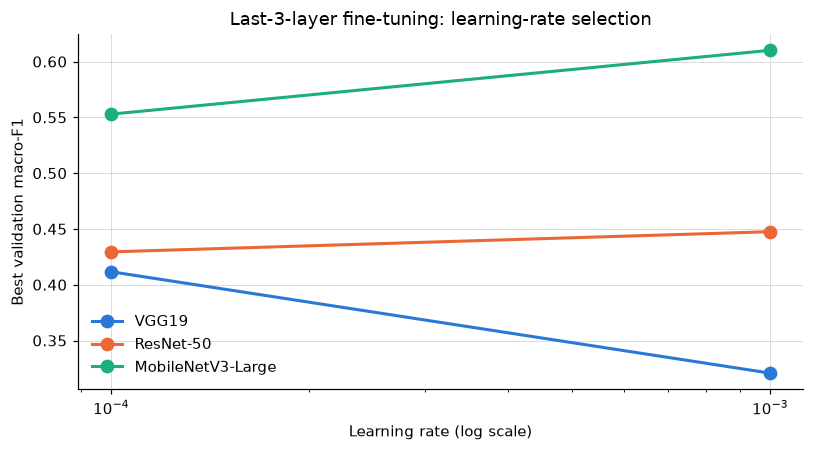

In [21]:
# Checkpoint 21: select the learning rate for each backbone by validation macro-F1.
lr_table = PART2.table([f"{b}_last3_lr{lr_tag(lr)}" for b in BACKBONES for lr in LAST3_LRS])
lr_view = lr_table[["backbone", "learning_rate", "trainable_parameters", "best_epoch", "stopped_epoch",
                    "validation_loss", "validation_accuracy", "validation_macro_f1"]].copy()
lr_view["backbone"] = lr_view["backbone"].map(BACKBONE_LABELS)
lr_view.to_csv(RESULTS_DIR / "last3_learning_rate_selection.csv", index=False)
display(lr_view.style.format({"learning_rate": "{:.0e}", "trainable_parameters": "{:,}",
                              "validation_loss": "{:.4f}", "validation_accuracy": "{:.4f}",
                              "validation_macro_f1": "{:.4f}"}).hide(axis="index"))

LAST3_SELECTED = {}
for backbone in BACKBONES:
    rows = lr_table[lr_table["backbone"] == backbone].sort_values(["validation_macro_f1", "validation_loss"],
                                                                   ascending=[False, True])
    LAST3_SELECTED[backbone] = rows.iloc[0]["name"]
    print(f"SELECTED {BACKBONE_LABELS[backbone]}: lr={rows.iloc[0]['learning_rate']:.0e} "
          f"(validation macro-F1 {rows.iloc[0]['validation_macro_f1']:.4f})")

fig, axis = plt.subplots(figsize=(7.5, 4.2))
for color, backbone in zip(SERIES, BACKBONES):
    rows = lr_table[lr_table["backbone"] == backbone].sort_values("learning_rate")
    axis.plot(rows["learning_rate"], rows["validation_macro_f1"], marker="o", markersize=8, color=color,
              label=BACKBONE_LABELS[backbone])
axis.set_xscale("log")
axis.set(title="Last-3-layer fine-tuning: learning-rate selection", xlabel="Learning rate (log scale)",
         ylabel="Best validation macro-F1")
axis.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "last3_learning_rate_selection.png", bbox_inches="tight")
plt.show()

**Learning-rate result**

- **VGG19 needs 1e-4** (0.412 vs 0.321): its last three layers hold 120 M pretrained parameters, which 1e-3 damages.
- **ResNet-50 and MobileNetV3 prefer 1e-3:** they fine-tune few parameters (3.4 M and 1.4 M), and 1e-4 adapts too slowly in 12 epochs.

## 2.3 Add new layers on a frozen backbone

New head: `Linear(512) → BN → ReLU → Dropout(0.5) → Linear(256) → BN → ReLU → Dropout(0.5) → Linear(7)`.

The backbone is fully frozen, and only the head is trained, with learning rate 1e-3.

In [22]:
# Checkpoint 22: train the added layers on each frozen backbone.
EXTENDED_LR = 1e-3
print(build_transfer_model("resnet50", "extended", NUM_CLASSES, pretrained=False).network.fc)
for backbone in BACKBONES:
    run_transfer(f"{backbone}_extended", backbone, "extended", EXTENDED_LR)
print("READY: added-layer runs completed")

Sequential(
  (0): Linear(in_features=2048, out_features=512, bias=True)
  (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=512, out_features=256, bias=True)
  (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): Dropout(p=0.5, inplace=False)
  (8): Linear(in_features=256, out_features=7, bias=True)
)
LOADED vgg19_extended: trained earlier; epoch log from results/milestone_03/part2_transfer/logs/vgg19_extended.csv (* = restored epoch)
Epoch 01 | lr 1.00e-03 | train loss 1.7782 acc 0.3027 F1 0.1923 | val loss 1.6574 acc 0.2976 F1 0.2054
Epoch 02 | lr 1.00e-03 | train loss 1.6265 acc 0.4168 F1 0.2486 | val loss 1.8198 acc 0.2470 F1 0.1549
Epoch 03 | lr 1.00e-03 | train loss 1.5135 acc 0.3809 F1 0.2554 | val loss 1.6119 acc 0.3325 F1 0.2253
Epoch 04 | lr 1.00e-03 | train loss 1.

## 2.4 Test evaluation and best model

All nine configurations are fixed and tested, as required. The **best model is chosen by validation macro-F1**, not test, and saved as a full checkpoint.

In [23]:
# Checkpoint 23: evaluate the nine final transfer models on the test split.
FINAL_TRANSFER_RUNS = {}
for backbone in BACKBONES:
    FINAL_TRANSFER_RUNS[(backbone, "head")] = f"{backbone}_head"
    FINAL_TRANSFER_RUNS[(backbone, "last3")] = LAST3_SELECTED[backbone]
    FINAL_TRANSFER_RUNS[(backbone, "extended")] = f"{backbone}_extended"

tl_test_loader = transfer_loaders(splits=("test",))["test"]
transfer_rows, transfer_test_outputs = [], {}
for (backbone, strategy), name in FINAL_TRANSFER_RUNS.items():
    summary = PART2.summary(name)
    model = load_transfer(name)
    test = evaluate(model, tl_test_loader, criterion, DEVICE, USE_AMP)
    transfer_test_outputs[name] = test
    transfer_rows.append({
        "run": name, "backbone": BACKBONE_LABELS[backbone], "strategy": STRATEGY_LABELS[strategy],
        "learning_rate": summary["learning_rate"], "trainable_parameters": summary["trainable_parameters"],
        "best_epoch": summary["best_epoch"], "validation_macro_f1": summary["validation_macro_f1"],
        "validation_accuracy": summary["validation_accuracy"], "test_loss": test["loss"],
        "test_accuracy": test["accuracy"], "test_macro_f1": test["macro_f1"],
    })
    del model
    gc.collect(); torch.cuda.empty_cache()

transfer_results = pd.DataFrame(transfer_rows)
transfer_results.to_csv(RESULTS_DIR / "transfer_learning_results.csv", index=False)
display(transfer_results.drop(columns="run").style.format({
    "learning_rate": "{:.0e}", "trainable_parameters": "{:,}", "validation_macro_f1": "{:.4f}",
    "validation_accuracy": "{:.4f}", "test_loss": "{:.4f}", "test_accuracy": "{:.4f}", "test_macro_f1": "{:.4f}",
}).highlight_max(subset=["validation_macro_f1"], color="#d6e6f8").hide(axis="index"))

BEST_TRANSFER_RUN = transfer_results.sort_values("validation_macro_f1", ascending=False).iloc[0]["run"]
best_transfer_row = transfer_results.set_index("run").loc[BEST_TRANSFER_RUN]
print(f"SELECTED by validation macro-F1: {BEST_TRANSFER_RUN} "
      f"(validation {best_transfer_row['validation_macro_f1']:.4f}, test {best_transfer_row['test_macro_f1']:.4f})")

backbone,strategy,learning_rate,trainable_parameters,best_epoch,validation_macro_f1,validation_accuracy,test_loss,test_accuracy,test_macro_f1
VGG19,Classifier only,1e-03,"28,679",6,0.2926,0.4779,1.3737,0.4823,0.3163
VGG19,Last 3 layers,1e-04,"119,574,535",6,0.4117,0.5933,1.1044,0.6006,0.4055
VGG19,Added layers,1e-03,"2,232,327",10,0.2433,0.3531,1.5300,0.3560,0.2383
ResNet-50,Classifier only,1e-03,"14,343",9,0.4420,0.6588,0.9743,0.6560,0.4514
ResNet-50,Last 3 layers,1e-03,"3,422,215",3,0.4475,0.6344,1.0121,0.6256,0.4108
ResNet-50,Added layers,1e-03,"1,183,751",3,0.4190,0.6170,1.0290,0.6066,0.4009
MobileNetV3-Large,Classifier only,1e-03,"8,967",9,0.4614,0.6425,0.9628,0.6525,0.4565
MobileNetV3-Large,Last 3 layers,1e-03,"1,392,647",8,0.6101,0.7211,0.8265,0.7024,0.5640
MobileNetV3-Large,Added layers,1e-03,"790,535",7,0.4415,0.5777,1.0543,0.5731,0.4255


SELECTED by validation macro-F1: mobilenet_v3_large_last3_lr1em03 (validation 0.6101, test 0.5640)


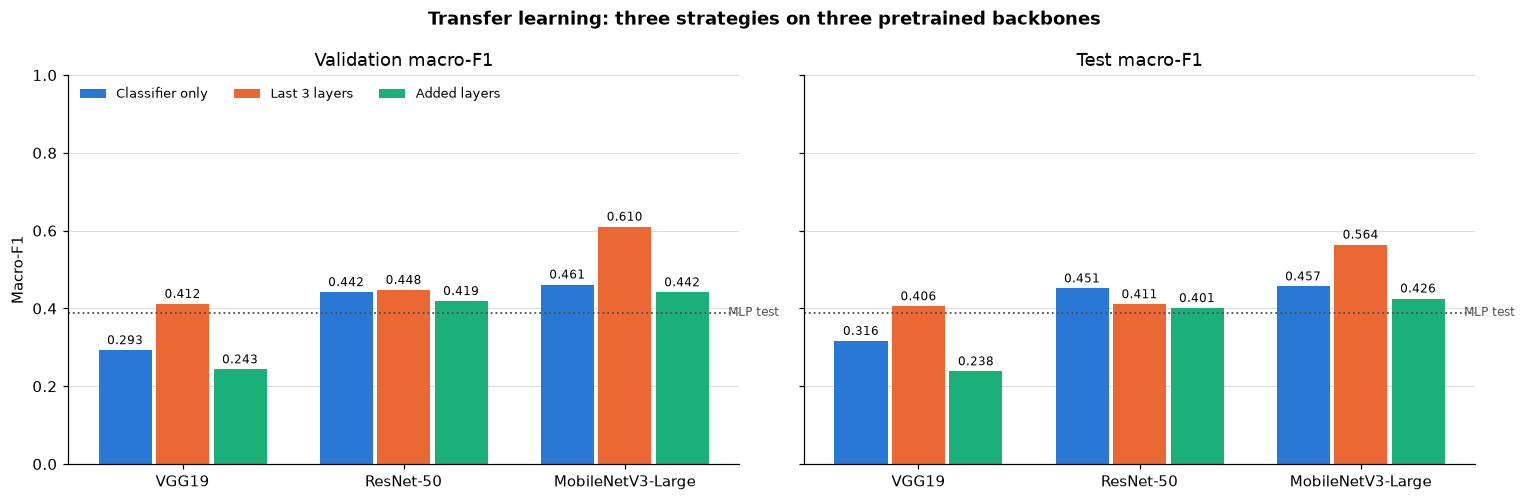

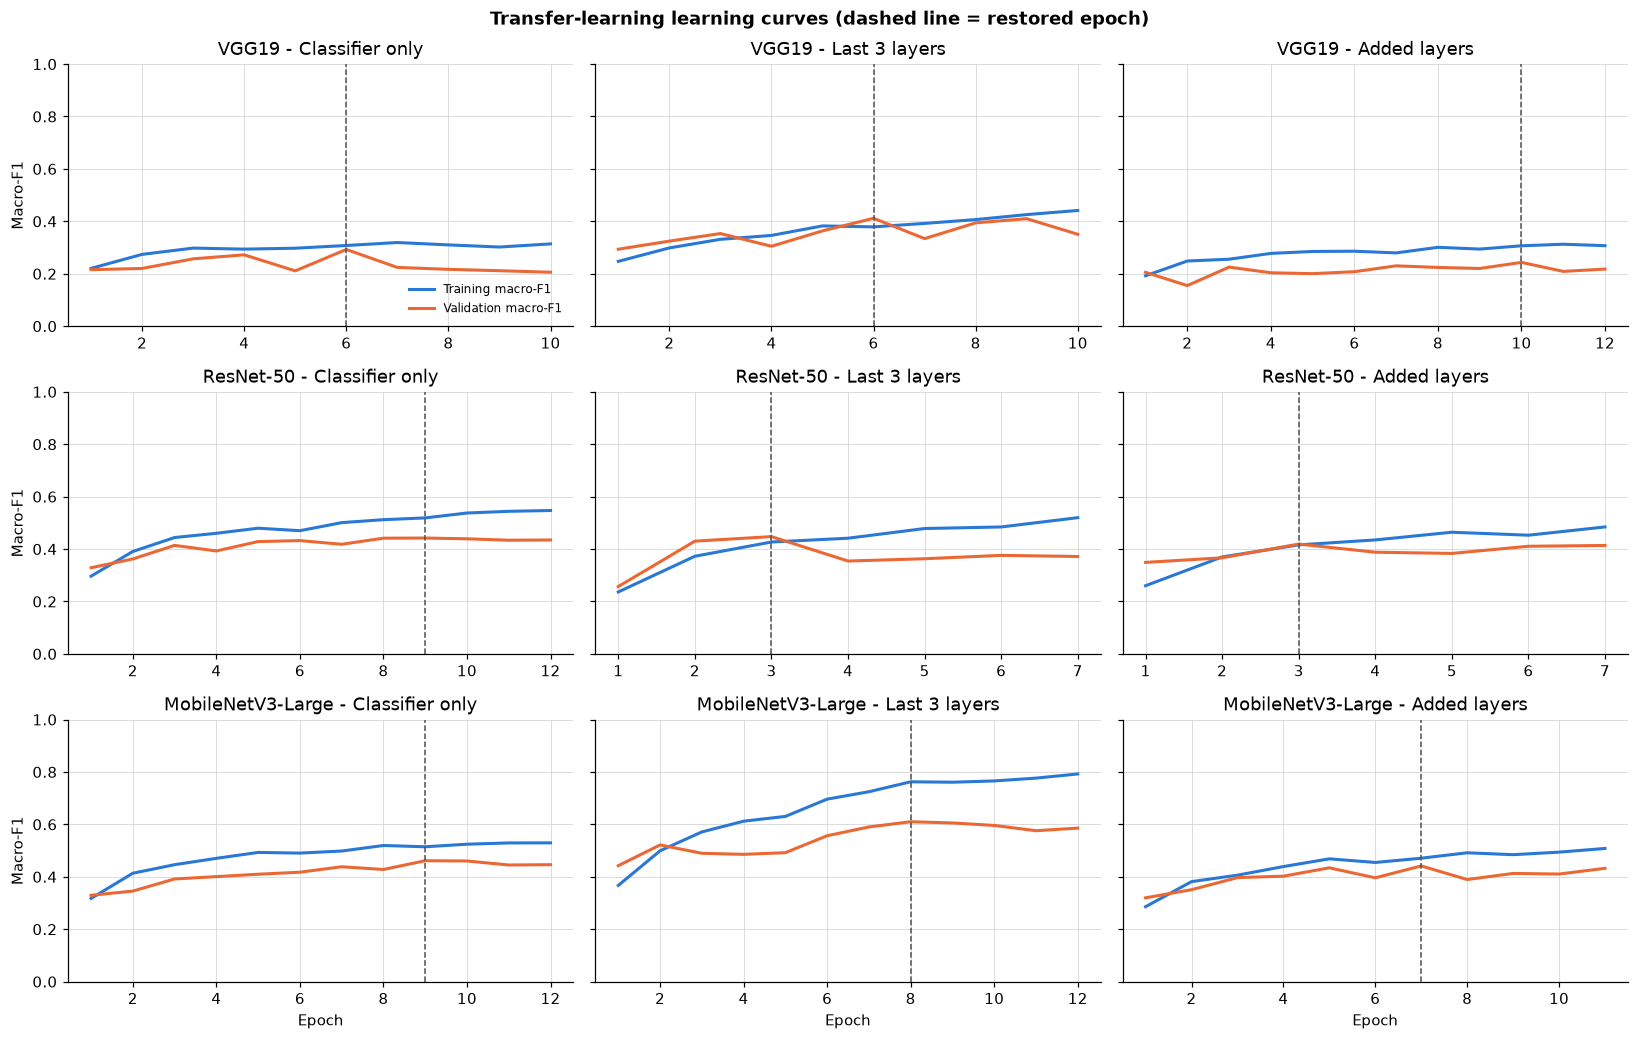

In [24]:
# Checkpoint 24: compare strategies and backbones; learning curves of all nine models.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
width = 0.26
positions = np.arange(len(BACKBONES))
for axis, metric, title in zip(axes, ["validation_macro_f1", "test_macro_f1"], ["Validation macro-F1", "Test macro-F1"]):
    for offset, (color, strategy) in enumerate(zip(SERIES, STRATEGY_LABELS.values())):
        values = [transfer_results[(transfer_results["backbone"] == BACKBONE_LABELS[b]) &
                                   (transfer_results["strategy"] == strategy)][metric].iloc[0] for b in BACKBONES]
        bars = axis.bar(positions + (offset - 1) * width, values, width - 0.02, color=color, label=strategy)
        axis.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    axis.axhline(MLP_TEST["test_macro_f1"], color="#52514e", linestyle=":", linewidth=1.2)
    axis.text(positions[-1] + 0.45, MLP_TEST["test_macro_f1"], " MLP test", va="center", fontsize=8, color="#52514e")
    axis.set_xticks(positions, [BACKBONE_LABELS[b] for b in BACKBONES])
    axis.set(title=title, ylim=(0, 1))
    axis.grid(axis="x", visible=False)
axes[0].set_ylabel("Macro-F1")
axes[0].legend(frameon=False, loc="upper left", ncols=3, fontsize=8.5)
fig.suptitle("Transfer learning: three strategies on three pretrained backbones", weight="bold")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "transfer_learning_comparison.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(len(BACKBONES), 3, figsize=(15, 3.2 * len(BACKBONES)), sharey=True)
for row, backbone in enumerate(BACKBONES):
    for col, strategy in enumerate(STRATEGY_LABELS):
        name = FINAL_TRANSFER_RUNS[(backbone, strategy)]
        history = PART2.history(name)
        axis = axes[row, col]
        axis.plot(history["epoch"], history["train_macro_f1"], color=TRAIN_COLOR, label="Training macro-F1")
        axis.plot(history["epoch"], history["validation_macro_f1"], color=VAL_COLOR, label="Validation macro-F1")
        axis.axvline(PART2.summary(name)["best_epoch"], color="#52514e", linestyle="--", linewidth=1)
        axis.set(title=f"{BACKBONE_LABELS[backbone]} - {STRATEGY_LABELS[strategy]}", ylim=(0, 1))
        if row == len(BACKBONES) - 1:
            axis.set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Macro-F1")
axes[0, 0].legend(frameon=False, loc="lower right", fontsize=8)
fig.suptitle("Transfer-learning learning curves (dashed line = restored epoch)", weight="bold")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "transfer_learning_curves.png", bbox_inches="tight")
plt.show()

### Transfer-learning result

- **Classifier only:** frozen MobileNetV3 and ResNet-50 features already match the scratch CNN (0.457, 0.451). VGG19's features transfer poorly (0.316).
- **Last 3 layers:** the largest gain. **MobileNetV3-Large is the best model (validation 0.610, test 0.564).**
- **Added layers:** did not beat a single linear layer within 12 epochs. Adapting pretrained layers matters more than adding new ones.
- **ResNet-50** was slightly better with last-3 on validation but worse on test, which is within single-seed noise.
- **MobileNetV3** won with every strategy, despite being the smallest backbone.

In [25]:
# Checkpoint 25: save the best-performing transfer model as a complete checkpoint.
best_model = load_transfer(BEST_TRANSFER_RUN)
best_summary = PART2.summary(BEST_TRANSFER_RUN)
BEST_TRANSFER_PATH = PART2.checkpoint_dir / "best_transfer.pt"
torch.save({
    "model_state_dict": {k: v.cpu() for k, v in best_model.state_dict().items()},
    "backbone": best_summary["backbone"], "strategy": best_summary["strategy"],
    "source_run": BEST_TRANSFER_RUN, "summary": best_summary,
    "normalization": {"mean": IMAGENET_MEAN, "std": IMAGENET_STD}, "image_size": TRANSFER_IMAGE_SIZE,
}, BEST_TRANSFER_PATH)

check_model = build_transfer_model(best_summary["backbone"], best_summary["strategy"], NUM_CLASSES, pretrained=False)
check_model.load_state_dict(torch.load(BEST_TRANSFER_PATH, map_location="cpu", weights_only=False)["model_state_dict"])
check_test = evaluate(check_model.to(DEVICE), tl_test_loader, criterion, DEVICE, USE_AMP)
assert abs(check_test["macro_f1"] - transfer_test_outputs[BEST_TRANSFER_RUN]["macro_f1"]) < 1e-6
del check_model
print(f"READY: saved {BEST_TRANSFER_PATH.relative_to(PROJECT_ROOT)} "
      f"({BEST_TRANSFER_PATH.stat().st_size / 2**20:.0f} MiB); reload verified")

READY: saved results/milestone_03/part2_transfer/checkpoints/best_transfer.pt (16 MiB); reload verified


## 2.5 Best model as a feature extractor

The input to the best model's final layer (1,280 features) is extracted without augmentation and standardized on training data. Three classifiers with balanced class weights are tuned on validation data, then tested:

| Classifier | Searched |
|---|---|
| SVM (RBF) | C ∈ {0.1, 1, 10} |
| Random forest (500 trees) | max depth ∈ {None, 20}, min leaf ∈ {1, 5} |
| Logistic regression | C ∈ {0.01, 0.1, 1} |

In [26]:
# Checkpoint 26: extract penultimate features with the best transfer model.
feature_loaders = transfer_loaders(splits=("train", "validation", "test"), augment_train=False, shuffle_train=False)
features, labels = {}, {}
started = time.perf_counter()
for split, loader in feature_loaders.items():
    features[split], labels[split] = extract_features(best_model, loader, DEVICE, USE_AMP)
for split in features:
    expected = split_manifest.loc[split_manifest["split"] == split, "dx"].map(label_to_index).to_numpy()
    assert np.array_equal(labels[split], expected), f"Label order mismatch in {split}"
display(pd.DataFrame([{"split": s, "images": features[s].shape[0], "feature_dimension": features[s].shape[1]}
                      for s in features]).style.hide(axis="index"))
print(f"READY: features extracted from {BEST_TRANSFER_RUN} in {time.perf_counter() - started:.1f}s")

split,images,feature_dimension
train,6409,1280
validation,1603,1280
test,2003,1280


READY: features extracted from mobilenet_v3_large_last3_lr1em03 in 5.2s


In [27]:
# Checkpoint 27: fit classical classifiers; choose hyperparameters on the validation split.
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

scaler = StandardScaler().fit(features["train"])
X = {split: scaler.transform(values) for split, values in features.items()}
y = labels

CLASSIFIER_GRID = {
    "SVM (RBF)": [{"C": c} for c in (0.1, 1.0, 10.0)],
    "Random forest": [{"max_depth": d, "min_samples_leaf": leaf} for d in (None, 20) for leaf in (1, 5)],
    "Logistic regression": [{"C": c} for c in (0.01, 0.1, 1.0)],
}

def make_classifier(kind, params):
    if kind == "SVM (RBF)":
        return SVC(kernel="rbf", gamma="scale", class_weight="balanced", random_state=SEED, **params)
    if kind == "Random forest":
        return RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample", n_jobs=-1,
                                      random_state=SEED, **params)
    return LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEED, **params)

search_rows, best_classifiers = [], {}
for kind, grid in CLASSIFIER_GRID.items():
    best_score = -1.0
    for params in grid:
        started = time.perf_counter()
        classifier = make_classifier(kind, params).fit(X["train"], y["train"])
        predictions = classifier.predict(X["validation"])
        score = f1_score(y["validation"], predictions, average="macro")
        search_rows.append({"classifier": kind, "params": json.dumps(params), "validation_macro_f1": score,
                            "validation_accuracy": accuracy_score(y["validation"], predictions),
                            "fit_seconds": time.perf_counter() - started})
        if score > best_score:
            best_score, best_classifiers[kind] = score, (params, classifier)
search_table = pd.DataFrame(search_rows)
search_table.to_csv(RESULTS_DIR / "feature_classifier_search.csv", index=False)
display(search_table.style.format({"validation_macro_f1": "{:.4f}", "validation_accuracy": "{:.4f}",
                                   "fit_seconds": "{:.1f}"}).hide(axis="index"))
for kind, (params, _) in best_classifiers.items():
    print(f"SELECTED {kind}: {params}")

classifier,params,validation_macro_f1,validation_accuracy,fit_seconds
SVM (RBF),"{""C"": 0.1}",0.5985,0.6769,18.1
SVM (RBF),"{""C"": 1.0}",0.6336,0.7542,9.7
SVM (RBF),"{""C"": 10.0}",0.6335,0.7960,8.3
Random forest,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.5697,0.7773,6.3
Random forest,"{""max_depth"": null, ""min_samples_leaf"": 5}",0.6409,0.7848,5.2
Random forest,"{""max_depth"": 20, ""min_samples_leaf"": 1}",0.5743,0.7785,5.8
Random forest,"{""max_depth"": 20, ""min_samples_leaf"": 5}",0.6279,0.7829,5.2
Logistic regression,"{""C"": 0.01}",0.6304,0.7679,24.6
Logistic regression,"{""C"": 0.1}",0.6101,0.7773,26.2
Logistic regression,"{""C"": 1.0}",0.6024,0.7686,15.2


SELECTED SVM (RBF): {'C': 1.0}
SELECTED Random forest: {'max_depth': None, 'min_samples_leaf': 5}
SELECTED Logistic regression: {'C': 0.01}


classifier,selected_params,validation_macro_f1,test_accuracy,test_macro_f1
End-to-end network (mobilenet_v3_large_last3_lr1em03),-,0.6101,0.7024,0.5640
SVM (RBF) on extracted features,"{""C"": 1.0}",0.6336,0.7554,0.5987
Random forest on extracted features,"{""max_depth"": null, ""min_samples_leaf"": 5}",0.6409,0.7778,0.5771
Logistic regression on extracted features,"{""C"": 0.01}",0.6304,0.7609,0.5996


Best feature-based classifier by validation macro-F1: Random forest
              precision    recall  f1-score   support

       akiec      0.417     0.379     0.397        66
         bcc      0.571     0.660     0.613       103
         bkl      0.543     0.636     0.586       220
          df      0.417     0.217     0.286        23
         mel      0.529     0.365     0.432       222
          nv      0.889     0.904     0.896      1341
        vasc      0.730     0.964     0.831        28

    accuracy                          0.778      2003
   macro avg      0.585     0.589     0.577      2003
weighted avg      0.771     0.778     0.772      2003



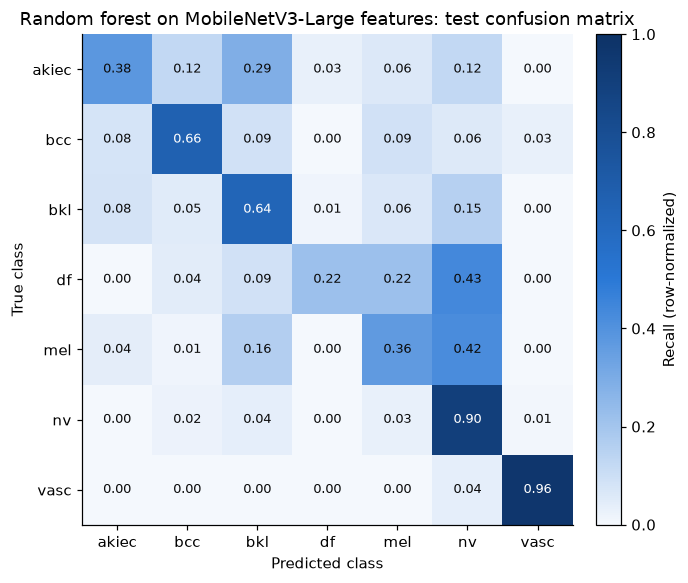

In [28]:
# Checkpoint 28: test evaluation of the feature-based classifiers vs. the end-to-end network.
feature_rows = []
end_to_end = transfer_test_outputs[BEST_TRANSFER_RUN]
feature_rows.append({"classifier": f"End-to-end network ({BEST_TRANSFER_RUN})", "selected_params": "-",
                     "validation_macro_f1": best_summary["validation_macro_f1"],
                     "test_accuracy": end_to_end["accuracy"], "test_macro_f1": end_to_end["macro_f1"]})
feature_predictions = {}
for kind, (params, classifier) in best_classifiers.items():
    predictions = classifier.predict(X["test"])
    feature_predictions[kind] = predictions
    feature_rows.append({
        "classifier": f"{kind} on extracted features", "selected_params": json.dumps(params),
        "validation_macro_f1": f1_score(y["validation"], classifier.predict(X["validation"]), average="macro"),
        "test_accuracy": accuracy_score(y["test"], predictions),
        "test_macro_f1": f1_score(y["test"], predictions, average="macro"),
    })
feature_results = pd.DataFrame(feature_rows)
feature_results.to_csv(RESULTS_DIR / "feature_extractor_results.csv", index=False)
display(feature_results.style.format({"validation_macro_f1": "{:.4f}", "test_accuracy": "{:.4f}",
                                      "test_macro_f1": "{:.4f}"}).hide(axis="index"))

best_feature_kind = max(best_classifiers, key=lambda k: f1_score(
    y["validation"], best_classifiers[k][1].predict(X["validation"]), average="macro"))
print(f"Best feature-based classifier by validation macro-F1: {best_feature_kind}")
print(classification_report(y["test"], feature_predictions[best_feature_kind], labels=list(range(NUM_CLASSES)),
                            target_names=class_codes, digits=3, zero_division=0))
plot_confusion(y["test"], feature_predictions[best_feature_kind],
               f"{best_feature_kind} on {BACKBONE_LABELS[best_summary['backbone']]} features: test confusion matrix",
               FIGURE_DIR / "feature_classifier_confusion_matrix.png")

### Feature-extractor result

- **All three classifiers beat the network's own head** on validation and test: test macro-F1 0.577–0.600 vs 0.564; accuracy up to 0.778.
- **Selection vs test:** the random forest was selected on validation (0.641), but SVM and logistic regression scored slightly higher on test. Small validation differences do not always carry over.

# 3. Overall comparison

approach,test_accuracy,test_macro_f1
"MLP (Shallow MLP, Milestone 2)",0.5861,0.3890
CNN from scratch,0.5821,0.4537
Transfer: classifier only (MobileNetV3-Large),0.6525,0.4565
Transfer: last 3 layers (MobileNetV3-Large),0.7024,0.5640
Transfer: added layers (MobileNetV3-Large),0.5731,0.4255
Random forest on MobileNetV3-Large features,0.7778,0.5771


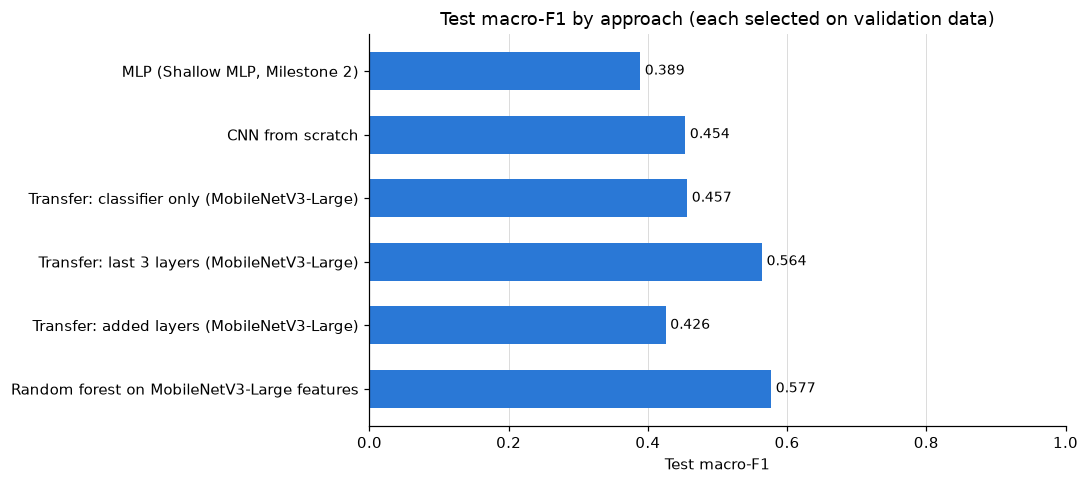

READY: Milestone 3 workflow complete; all required outputs exist


In [29]:
# Checkpoint 29: overall test comparison across milestones and approaches.
overall = [
    {"approach": f"MLP ({MLP_TEST['network']}, Milestone 2)", "test_accuracy": MLP_TEST["test_accuracy"],
     "test_macro_f1": MLP_TEST["test_macro_f1"]},
    {"approach": "CNN from scratch", "test_accuracy": cnn_test["accuracy"], "test_macro_f1": cnn_test["macro_f1"]},
]
for strategy, label in STRATEGY_LABELS.items():
    rows = transfer_results[transfer_results["strategy"] == label].sort_values("validation_macro_f1", ascending=False)
    top = rows.iloc[0]
    overall.append({"approach": f"Transfer: {label.lower()} ({top['backbone']})",
                    "test_accuracy": top["test_accuracy"], "test_macro_f1": top["test_macro_f1"]})
top_feature = feature_results[feature_results["classifier"].str.startswith(best_feature_kind)].iloc[0]
overall.append({"approach": f"{best_feature_kind} on {BACKBONE_LABELS[best_summary['backbone']]} features",
                "test_accuracy": top_feature["test_accuracy"], "test_macro_f1": top_feature["test_macro_f1"]})
overall = pd.DataFrame(overall)
overall.to_csv(RESULTS_DIR / "overall_test_comparison.csv", index=False)
display(overall.style.format({"test_accuracy": "{:.4f}", "test_macro_f1": "{:.4f}"}).hide(axis="index"))

fig, axis = plt.subplots(figsize=(10, 0.55 * len(overall) + 1.2))
order = overall.iloc[::-1]
bars = axis.barh(order["approach"], order["test_macro_f1"], color=SERIES[0], height=0.6)
axis.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
axis.set(title="Test macro-F1 by approach (each selected on validation data)", xlabel="Test macro-F1", xlim=(0, 1))
axis.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "overall_test_comparison.png", bbox_inches="tight")
plt.show()

required_outputs = [
    FIGURE_DIR / "augmentation_examples.png", FIGURE_DIR / "cnn_architecture.png",
    RESULTS_DIR / "hyperparameter_tuning.csv", RESULTS_DIR / "early_stopping_comparison.csv",
    PART1.checkpoint_dir / "cnn_best.pt", PART1.log_dir / "cnn_best.csv",
    RESULTS_DIR / "transfer_learning_results.csv", PART2.checkpoint_dir / "best_transfer.pt",
    RESULTS_DIR / "feature_extractor_results.csv", RESULTS_DIR / "overall_test_comparison.csv",
]
missing = [str(p.relative_to(PROJECT_ROOT)) for p in required_outputs if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing outputs: {missing}")
print("READY: Milestone 3 workflow complete; all required outputs exist")

## 4. Conclusions

| Approach | Test macro-F1 |
|---|---|
| Shallow MLP (Milestone 2) | 0.389 |
| CNN from scratch | 0.454 |
| MobileNetV3, classifier only | 0.457 |
| MobileNetV3, last 3 layers | 0.564 |
| Random forest on MobileNetV3 features | 0.577 |

1. The CNN beats the MLP: spatial structure matters.
2. Pretrained features help further, and fine-tuning the last layers gives the largest gain.
3. Larger pretrained layers need a smaller learning rate.
4. Classical classifiers on the learned features add a further improvement.

**Limitations:** single seed and split; 12-epoch transfer budget; HAM10000 results do not indicate clinical performance.

## Reproducibility

- Fixed Milestone 2 split, seed 471.
- Part 1: 128 px, training-only normalization. Part 2: 224 px, ImageNet normalization.
- Weighted cross-entropy, Adam (weight decay 1e-4), batch 64, LR halved on plateau.
- All logs, summaries, and checkpoints are in `results/milestone_03/`.
- Test data is used only after validation-based choices.